# Perceived employability of senior executives

Ali Ulas CAVUSOGLU · 2026

## Table of contents

0. Setup
1. Exploratory Data Analysis
   - 1.1 Data quality and respondent profile
   - 1.2 The 12 employability scores
   - 1.3 Scores and personal variables
2. Preparing the data
   - 2.1 Rare categories
   - 2.2 Salary
   - 2.3 Almost-constant variables
   - 2.4 Family situation and children
   - 2.5 Encoding
   - 2.6 Final check
3. What drives professional self-efficacy?
   - 3.1 Choice of predictors
   - 3.2 Linear regression
   - 3.3 Standardised coefficients
   - 3.4 Checking the assumptions
   - 3.5 Limits of ranking the predictors
4. Who are the job seekers?
   - 4.1 Class balance and baseline
   - 4.2 Choice of predictors
   - 4.3 Logistic regression
   - 4.4 Evaluation on a test set
   - 4.5 Prediction is not causation
5. Summary of results

## 0. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import pingouin as pg
from scipy.stats import chi2_contingency

### Helper functions

The five helper functions below are used throughout the analysis for univariate and bivariate descriptions.

In [2]:
# Helper function UniCat 

def UniCat(df: pd.DataFrame, col: str) -> pd.DataFrame:
    """
    Univariate analysis of a categorical variable
    Inputs : df (the dataset) and col (the name of the categorical variable)
    Returns the summary table (counts and proportions of each category)
    Plots a bar chart and a pie chart
    """

    counts = df[col].value_counts()
    props = df[col].value_counts(normalize=True)
    table = pd.DataFrame({"count": counts, "proportion": props})

    print(f"Missing values: {df[col].isna().sum()}")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].bar(table.index, table["count"])
    axes[0].set_title(f"Bar chart of {col}")
    axes[0].set_ylabel("Count")

    axes[1].pie(table["count"], labels=table.index, autopct="%1.1f%%")
    axes[1].set_title(f"Pie chart of {col}")

    plt.tight_layout()
    plt.show()

    return table


In [3]:
# Helper function UniQuant 

def UniQuant(df: pd.DataFrame, col:str, bins=10):
    '''
    Univariate analysis of a quantitative variable
    Inputs : df (the dataset), col (the name of the quantitative variable) and bins (the number of intervals)
    Returns the 5 number summary with the Tukey fences, and the frequency distribution table
    Plots a histogram and a boxplot
    '''

    x = df[col].dropna()

    # 5 number summary with the Tukey fences
    summary = x.describe().iloc[3:].copy()
    iqr = summary["75%"] - summary["25%"]
    summary["lower fence"] = summary["25%"] - 1.5 * iqr
    summary["upper fence"] = summary["75%"] + 1.5 * iqr

    # Frequency distribution table
    freq = pd.cut(x, bins=bins).value_counts(sort=False).to_frame("count")
    freq["proportion"] = freq["count"] / len(x)
    freq["cumulative"] = freq["proportion"].cumsum()

    # Plots
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].hist(x, bins=bins, edgecolor="black")
    axes[0].set_title(f"Histogram of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Count")

    sns.boxplot(x=x, ax=axes[1])
    axes[1].set_title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

    return summary, freq


In [4]:
# Helper function BivCat 

def BivCat (df: pd.DataFrame, col:str, row:str):
    '''
    Chi-square test of independence between two categorical variables
    Inputs : df (the dataset), col and row (the names of the two categorical variables)
    Returns a dictionary with the observed and expected contingency tables, the chi-square statistic and its p-value,
    the Pearson residuals (and the standardized residuals), Cramer's V and the share of expected counts below 5 (validity condition)
    Plots a side-by-side bar chart and a stacked bar chart
    '''

    observed = pd.crosstab(df[row], df[col])

    chi2, p, dof, exp = chi2_contingency(observed, correction=False)
    expected = pd.DataFrame(exp, index=observed.index, columns=observed.columns)

    # Pearson residuals
    pearson = (observed - expected) / np.sqrt(expected)

    # Standardised  residuals
    n = observed.values.sum()
    row_p = observed.sum(axis=1) / n
    col_p = observed.sum(axis=0) / n
    denom = np.sqrt(expected.values * np.outer(1 - row_p, 1 - col_p))
    standardized = pd.DataFrame((observed.values - expected.values) / denom,
                                index=observed.index, columns=observed.columns)

    # Cramer's V
    cramers_v = np.sqrt(chi2 / (n * (min(observed.shape) - 1)))

    # share of expected counts below 5
    share_below_5 = (expected.values < 5).mean()

    # Plots
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    observed.plot(kind="bar", ax=axes[0], rot=0)
    axes[0].set_title(f"Side-by-side: {row} by {col}")
    axes[0].set_ylabel("Count")
    observed.plot(kind="bar", stacked=True, ax=axes[1], rot=0)
    axes[1].set_title(f"Stacked: {row} by {col}")
    axes[1].set_ylabel("Count")
    plt.tight_layout()
    plt.show()

    return {
        "observed": observed,
        "expected": expected,
        "chi2": chi2,
        "p_value": p,
        "dof": dof,
        "pearson_residuals": pearson,
        "standardized_residuals": standardized,
        "cramers_v": cramers_v,
        "share_expected_below_5": share_below_5,
    }


In [5]:
# Helper function BivQuant 

def BivQuant(df:pd.DataFrame, method='pearson'):
    '''
    Correlation analysis of quantitative variables
    Inputs : df (the dataset, quantitative variables only) and method ('pearson' or 'spearman')
    Returns the correlation matrix and the matrix of p-values
    Plots both matrices as heatmaps
    '''

    pairs = pg.pairwise_corr(data=df, method=method, padjust=None)
    p_col = "p_unc" if "p_unc" in pairs.columns else "p-unc"  # pingouin version compatibility

    cols = df.columns
    corr = pd.DataFrame(np.eye(len(cols)), index=cols, columns=cols)
    pvals = pd.DataFrame(np.zeros((len(cols), len(cols))), index=cols, columns=cols)

    for _, r in pairs.iterrows():
        corr.loc[r["X"], r["Y"]] = corr.loc[r["Y"], r["X"]] = r["r"]
        pvals.loc[r["X"], r["Y"]] = pvals.loc[r["Y"], r["X"]] = r[p_col]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
    axes[0].set_title(f"Correlation matrix ({method})")
    sns.heatmap(pvals, annot=True, fmt=".2g", cmap="viridis_r", vmin=0, vmax=1, ax=axes[1])
    axes[1].set_title("p-values")
    plt.tight_layout()
    plt.show()

    sns.pairplot(df, diag_kind="kde")
    plt.show()

    return corr, pvals


In [6]:
# Helper function BivMixte 

def BivMixte(df: pd.DataFrame, dv:str, group:str, padjust: str = "bonferroni"):
    '''
    One-way ANOVA of a quantitative variable (dv) across the categories of a grouping variable (group)
    Returns the ANOVA table with the effect sizes eta2 (= SSB/SST) and omega2,
    and the pairwise (post hoc) t-tests with Cohen's d
    Plots the grouped boxplots
    '''

    anova = pg.anova(dv=dv, between=group, data=df, detailed=True)

    ssb = anova.loc[0, "SS"]
    ssw = anova.loc[1, "SS"]
    dfb = anova.loc[0, "DF"]
    msw = anova.loc[1, "MS"]
    sst = ssb + ssw

    anova["eta2"] = [ssb / sst, np.nan]
    anova["omega2"] = [(ssb - dfb * msw) / (sst + msw), np.nan]

    pairs = pg.pairwise_tests(dv=dv, between=group, data=df, effsize="cohen",
                              padjust=padjust, parametric=True)

    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df, x=group, y=dv)
    plt.title(f"{dv} by {group}")
    plt.show()

    return anova, pairs


### Loading the data

In [7]:
# Relative path to the data folder
DATA_DIR = Path('data')
df = pd.read_csv(DATA_DIR / 'employability.csv')

In [8]:
df.shape

(460, 23)

In [9]:
df.head(10)

,respondent,competence,anticipation,flexibility,job_search_techniques,self_efficacy,training,alternative_employment,value_awareness,market_knowledge,...,sex,job_status,education_place,education_level,degree_type,sector,family_status,age,children,salary_band
0,1,7.00,6.00,6.67,6.25,4.67,5.14,4.29,6.00,5.67,...,Male,Employed,France,Master (4-5 years),Business school,Finance & insurance,Couple with children,47,2,> 99k
1,2,7.00,7.00,6.00,6.50,2.67,4.57,1.00,5.50,5.33,...,Female,Employed,France,Beyond master (> 5 years),Business school,Other,Single,46,0,70-79k
2,3,7.00,5.33,7.00,7.00,1.00,4.57,5.43,4.50,6.00,...,Male,Job seeker,France,Beyond master (> 5 years),Business school,Finance & insurance,Couple with children,51,4,> 99k
3,4,7.00,7.00,5.00,7.00,1.00,4.14,2.43,4.50,7.00,...,Female,Job seeker,France,Beyond master (> 5 years),Business school,Information & communication,Couple with children,54,3,90-99k
4,5,6.00,5.00,5.00,3.75,3.67,4.57,3.71,4.75,4.33,...,Female,Job seeker,France,Master (4-5 years),Other,"Education, health & social work",Couple with children,55,1,< 20k
5,6,7.00,6.33,5.67,5.50,3.33,2.86,1.00,6.50,5.00,...,Male,Employed,France,Beyond master (> 5 years),Business school,Industry,Couple with children,53,1,> 99k
6,7,7.00,7.00,5.33,5.75,3.33,2.43,3.57,3.25,3.00,...,Female,Employed,France,Beyond master (> 5 years),Business school,Other,Couple with children,49,3,> 99k
7,8,7.00,5.67,5.33,6.50,5.33,5.00,3.00,6.50,5.67,...,Female,Employed,France,Beyond master (> 5 years),Other,Other,Couple with children,46,3,40-49k
8,9,5.67,4.00,3.33,3.00,2.33,2.86,3.43,4.50,3.00,...,Male,Employed,France,Beyond master (> 5 years),Business school,Information & communication,Couple with children,48,4,> 99k
9,10,6.00,4.67,4.67,3.50,2.67,3.57,1.00,4.00,5.33,...,Male,Employed,France,Beyond master (> 5 years),Business school,Finance & insurance,Couple with children,47,2,> 99k


## 1. Exploratory Data Analysis



### 1.1 Data quality and respondent profile

In [10]:
df.dtypes

respondent                  int64
competence                float64
anticipation              float64
flexibility               float64
job_search_techniques     float64
self_efficacy             float64
training                  float64
alternative_employment    float64
value_awareness           float64
market_knowledge          float64
versatility               float64
know_how_visibility       float64
networks                  float64
sex                           str
job_status                    str
education_place               str
education_level               str
degree_type                   str
sector                        str
family_status                 str
age                         int64
children                    int64
salary_band                   str
dtype: object

In [11]:
df.isna().sum()

respondent                0
competence                0
anticipation              0
flexibility               0
job_search_techniques     0
self_efficacy             0
training                  0
alternative_employment    0
value_awareness           0
market_knowledge          0
versatility               0
know_how_visibility       0
networks                  0
sex                       0
job_status                0
education_place           0
education_level           0
degree_type               0
sector                    0
family_status             0
age                       0
children                  0
salary_band               0
dtype: int64

In [12]:
# 12 Employability Scores

score_cols = ['competence', 'anticipation', 'flexibility', 'job_search_techniques',
              'self_efficacy', 'training', 'alternative_employment', 'value_awareness',
              'market_knowledge', 'versatility', 'know_how_visibility', 'networks']

In [13]:
# Checking if scores are between 1 and 7, age between 45 and 65, children between 0 and 4

limits = {}
for col in score_cols:
    limits[col] = (1, 7)
limits['age'] = (45, 65)
limits['children'] = (0, 4)

rows = []
for col, (low, high) in limits.items():
    rows.append({'variable': col,
                 'min': df[col].min(),
                 'max': df[col].max(),
                 'allowed range': f'{low} to {high}',
                 'all inside': df[col].between(low, high).all()})
range_check = pd.DataFrame(rows)
range_check

,variable,min,max,allowed range,all inside
0,competence,4.00,7.0,1 to 7,True
1,anticipation,3.33,7.0,1 to 7,True
2,flexibility,2.67,7.0,1 to 7,True
3,job_search_techniques,2.00,7.0,1 to 7,True
4,self_efficacy,1.00,7.0,1 to 7,True
5,training,1.29,7.0,1 to 7,True
6,alternative_employment,1.00,7.0,1 to 7,True
7,value_awareness,1.50,7.0,1 to 7,True
8,market_knowledge,1.00,7.0,1 to 7,True
9,versatility,1.00,7.0,1 to 7,True


In [14]:
# Count duplicated rows, ignoring the respondent number
cols_without_id = df.columns.drop('respondent')
df.duplicated(subset=cols_without_id).sum()

np.int64(3)

In [15]:
# all the duplicated rows, with each pair next to each other
duplicates = df[df.duplicated(subset=cols_without_id, keep=False)]
duplicates.sort_values(by=list(cols_without_id))

,respondent,competence,anticipation,flexibility,job_search_techniques,self_efficacy,training,alternative_employment,value_awareness,market_knowledge,...,sex,job_status,education_place,education_level,degree_type,sector,family_status,age,children,salary_band
389,390,5.67,6.33,5.67,6.25,3.00,4.00,1.00,6.25,5.67,...,Male,Employed,France,Beyond master (> 5 years),Business school,Industry,Couple with children,48,4,> 99k
432,433,5.67,6.33,5.67,6.25,3.00,4.00,1.00,6.25,5.67,...,Male,Employed,France,Beyond master (> 5 years),Business school,Industry,Couple with children,48,4,> 99k
359,360,6.33,6.00,5.67,4.75,1.67,4.86,5.86,5.25,6.00,...,Female,Employed,France,Beyond master (> 5 years),University,Other,Single,55,1,40-49k
366,367,6.33,6.00,5.67,4.75,1.67,4.86,5.86,5.25,6.00,...,Female,Employed,France,Beyond master (> 5 years),University,Other,Single,55,1,40-49k
97,98,6.67,5.33,4.00,3.25,1.67,4.00,1.71,4.75,3.00,...,Female,Employed,France,Beyond master (> 5 years),Engineering school,Industry,Single,53,0,> 99k
107,108,6.67,5.33,4.00,3.25,1.67,4.00,1.71,4.75,3.00,...,Female,Employed,France,Beyond master (> 5 years),Engineering school,Industry,Single,53,0,> 99k


NOTE: These 3 pairs (6 rows) are identical on every column, which is very unusual.


In [16]:
# Drop the 3 duplicated copies (keep the first row of each pair)
df = df.drop_duplicates(subset=cols_without_id, keep='first').reset_index(drop=True)
df.shape

(457, 23)

NOTE: We dropped the second row of each pair (respondents 108, 367 and 433). Two different people giving exactly the same answers on 22 variables, including 12 decimal scores, is not realistic, so these are double submissions. From here on the analysis uses 457 respondents.

#### Consistency between family_status and children

In [17]:
# Cross-tabulate family situation and number of dependent children
pd.crosstab(df['family_status'], df['children'], margins=True)

children,0,1,2,3,4,All
family_status,,,,,,
Couple,31,6,9,7,5,58
Couple with children,5,28,126,119,58,336
Single,37,8,12,3,3,63
All,73,42,147,129,66,457


#### Description of the respondents

In [18]:
# Natural order of the ordered variables (UniCat sorts by frequency)
orders = {
    'education_level': ['Bachelor (3 years)', 'Master (4-5 years)', 'Beyond master (> 5 years)'],
    'salary_band': ['< 20k', '20-29k', '30-39k', '40-49k', '50-59k',
                    '60-69k', '70-79k', '80-89k', '90-99k', '> 99k'],
    'children': [0, 1, 2, 3, 4],
}

Missing values: 0


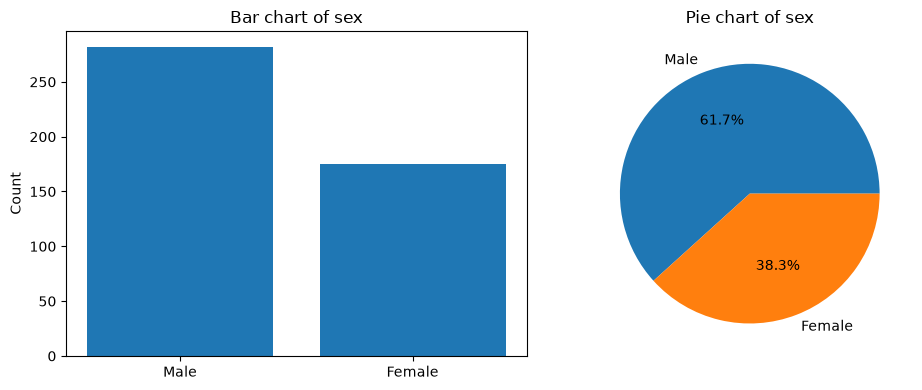

,count,proportion
sex,,
Male,282,0.617068
Female,175,0.382932


In [19]:
# gender distribution
UniCat(df, 'sex')

NOTE: 61.7% of the respondents are men and 38.3% are women. Both groups are large enough to compare them later.

Missing values: 0


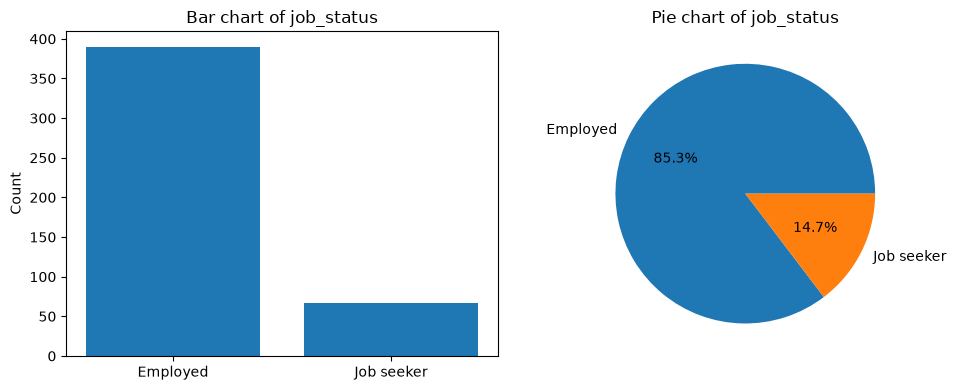

,count,proportion
job_status,,
Employed,390,0.853392
Job seeker,67,0.146608


In [20]:
# job status
UniCat(df, 'job_status')

NOTE : 390 respondents (85.3%) are employed and 67 (14.7%) are job seekers. The classes are unbalanced: a model that always predicts "Employed" would already be right 85.3% of the time. This is a baseline for logistic regression

Missing values: 0


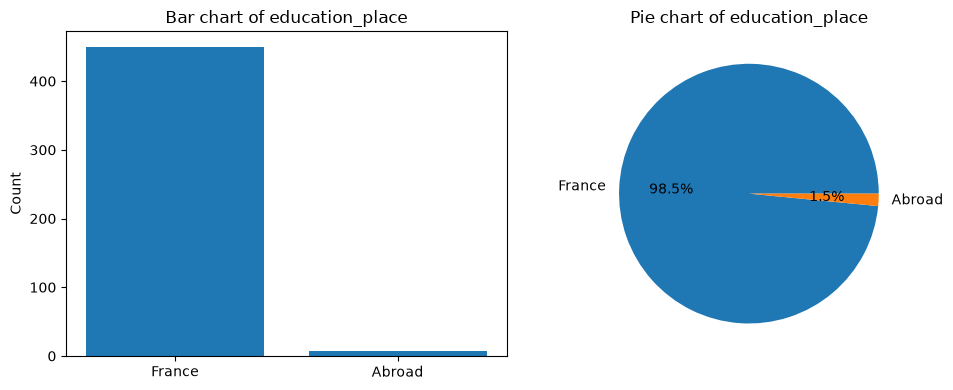

,count,proportion
education_place,,
France,450,0.984683
Abroad,7,0.015317


In [21]:
# country of the highest degree
UniCat(df, 'education_place')

NOTE: Almost everyone (450, 98.5%) got their degree in France and only 7 abroad. This variable is almost constant, so it carries very little information for us.

Missing values: 0


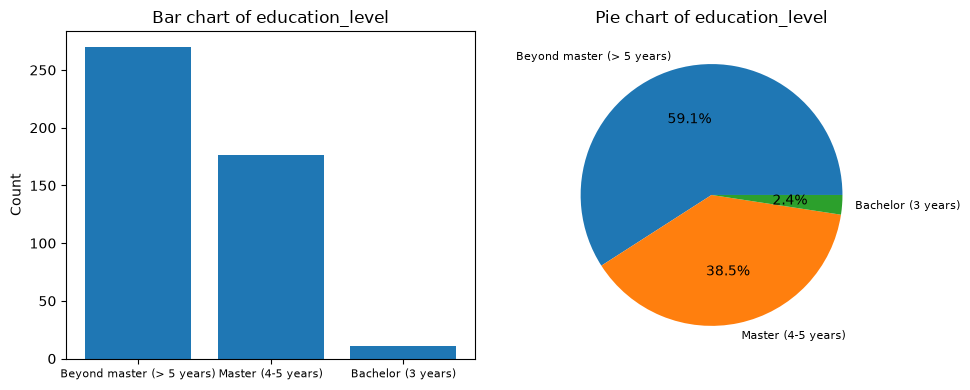

In [22]:
# smaller x labels (long names)
plt.rcParams['xtick.labelsize'] = 8
edu_table = UniCat(df, 'education_level')
plt.rcParams['xtick.labelsize'] = 10

In [23]:
# education level table in the natural order
edu_table = edu_table.reindex(orders['education_level'])
edu_table

,count,proportion
education_level,,
Bachelor (3 years),11,0.02407
Master (4-5 years),176,0.38512
Beyond master (> 5 years),270,0.59081


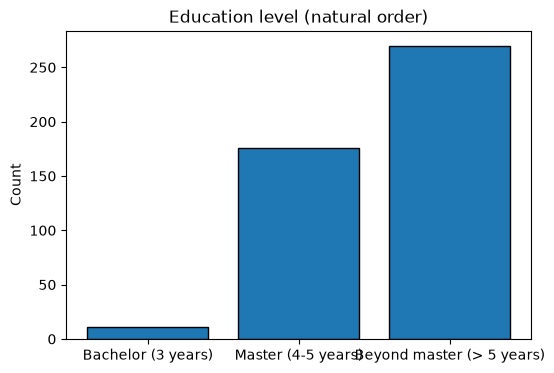

In [24]:
# Bar chart of the education level in the natural order
plt.figure(figsize=(6, 4))
plt.bar(edu_table.index, edu_table['count'], edgecolor='black')
plt.title('Education level (natural order)')
plt.ylabel('Count')
plt.show()

NOTE: The sample is very highly educated. 59.1% have studied more than 5 years after the BAC and 38.5% have a master degree. Only 11 respondents (2.4%) have only a bachelor's degree, so this category is very rare.

Missing values: 0


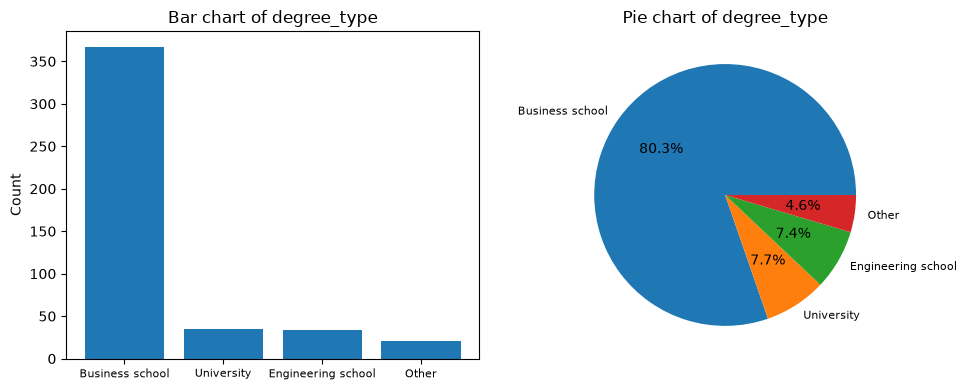

,count,proportion
degree_type,,
Business school,367,0.803063
University,35,0.076586
Engineering school,34,0.074398
Other,21,0.045952


In [25]:
# smaller x labels (long names)
plt.rcParams['xtick.labelsize'] = 8
table = UniCat(df, 'degree_type')
plt.rcParams['xtick.labelsize'] = 10
table

NOTE: 80.3% of the respondents come from a business school. Universities (7.7%), engineering schools (7.4%) and other degrees (4.6%) are small groups. This reflects how the sample was built (mostly graduates of one business school).

The sector names are long and overlap in the charts. For the charts only, we use a copy of the data (`df_plot`) with short sector names. The analysis itself always uses `df`.

In [26]:
# short sector names for charts only
short_sector = {
    'Finance & insurance': 'Finance',
    'Real estate': 'Real estate',
    'Construction': 'Constr.',
    'Education, health & social work': 'Edu/Health',
    'Industry': 'Industry',
    'Information & communication': 'IT/Comm',
    'Trade, transport, hotels & restaurants': 'Trade',
    'Business support services': 'Bus. supp.',
    'Other': 'Other',
}
df_plot = df.copy()
df_plot['sector'] = df_plot['sector'].replace(short_sector)

Missing values: 0


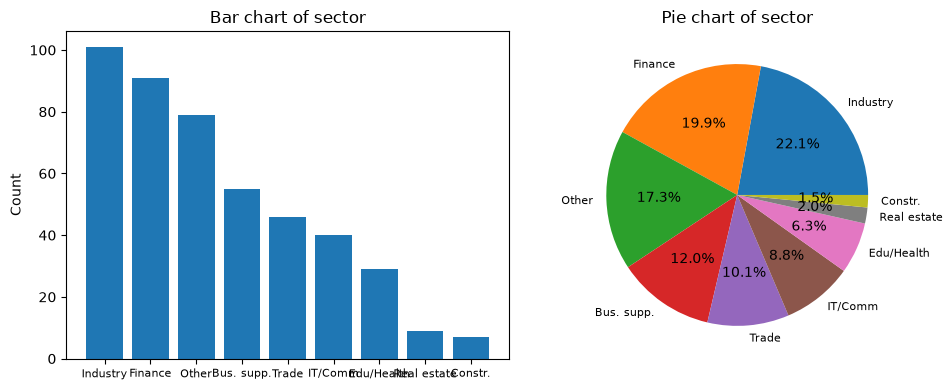

,count,proportion
sector,,
Industry,101,0.221007
Finance,91,0.199125
Other,79,0.172867
Bus. supp.,55,0.120350
Trade,46,0.100656
IT/Comm,40,0.087527
Edu/Health,29,0.063457
Real estate,9,0.019694
Constr.,7,0.015317


In [27]:
# short sector names, smaller x labels
plt.rcParams['xtick.labelsize'] = 8
table = UniCat(df_plot, 'sector')
plt.rcParams['xtick.labelsize'] = 10
table

NOTE: Industry (22.1%) and finance & insurance (19.9%) are the largest sectors. Real estate (9 respondents) and construction (7 respondents) are very rare. "Other" is large (17.3%) and mixes different activities, so it is hard to interpret.

Missing values: 0


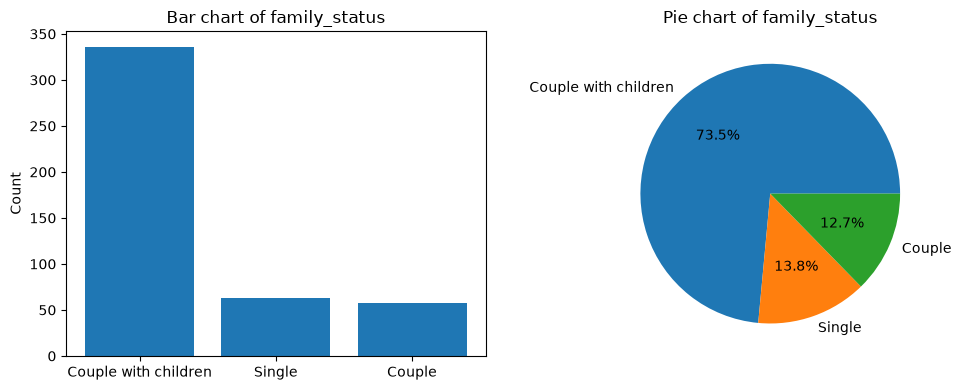

,count,proportion
family_status,,
Couple with children,336,0.735230
Single,63,0.137856
Couple,58,0.126915


In [28]:
# family situation
UniCat(df, 'family_status')

NOTE: Most respondents (73.5%) live in a couple with children. Singles (13.8%) and couples without children (12.7%) are smaller groups of similar size.

Missing values: 0


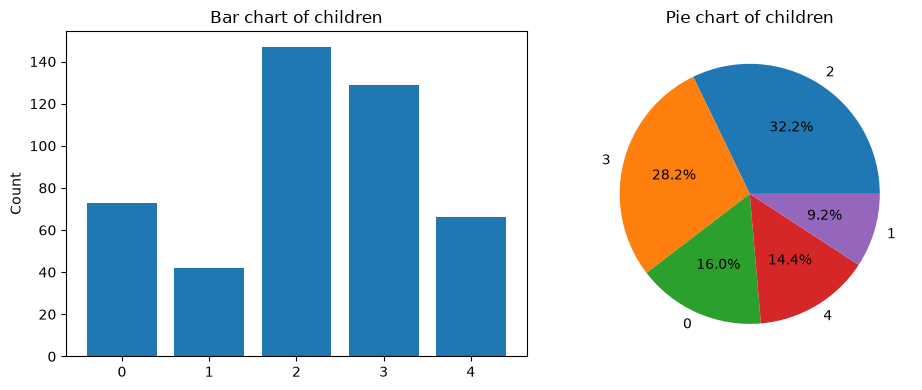

In [29]:
# Describe the number of dependent children
children_table = UniCat(df, 'children')

In [30]:
# children table in the natural order
children_table = children_table.reindex(orders['children'])
children_table

,count,proportion
children,,
0,73,0.159737
1,42,0.091904
2,147,0.321663
3,129,0.282276
4,66,0.144420


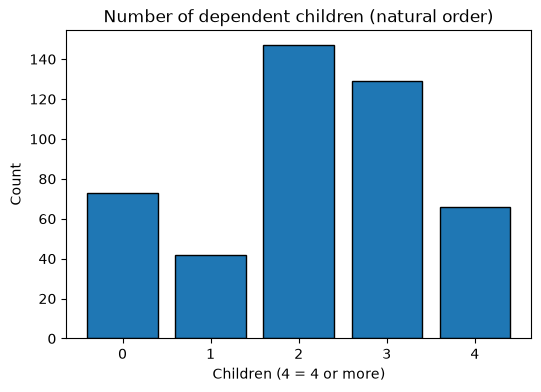

In [31]:
# Bar chart of the number of children in the natural order
plt.figure(figsize=(6, 4))
plt.bar(children_table.index.astype(str), children_table['count'], edgecolor='black')
plt.title('Number of dependent children (natural order)')
plt.xlabel('Children (4 = 4 or more)')
plt.ylabel('Count')
plt.show()

NOTE: Two children (32.2%) and three children (28.2%) are the most common answers. 16.0% have no dependent child and 14.4% have four or more. Families are rather large in this sample.

Missing values: 0


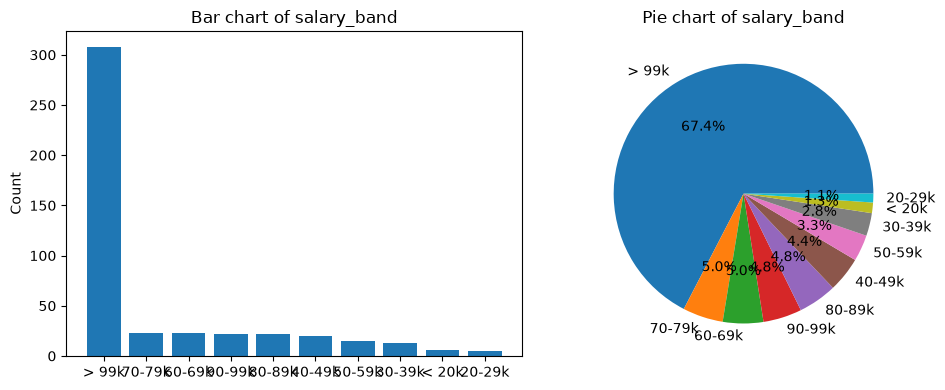

In [32]:
# salary band
salary_table = UniCat(df, 'salary_band')

In [33]:
# salary band table in band order
salary_table = salary_table.reindex(orders['salary_band'])
salary_table

,count,proportion
salary_band,,
< 20k,6,0.013129
20-29k,5,0.010941
30-39k,13,0.028446
40-49k,20,0.043764
50-59k,15,0.032823
60-69k,23,0.050328
70-79k,23,0.050328
80-89k,22,0.048140
90-99k,22,0.048140


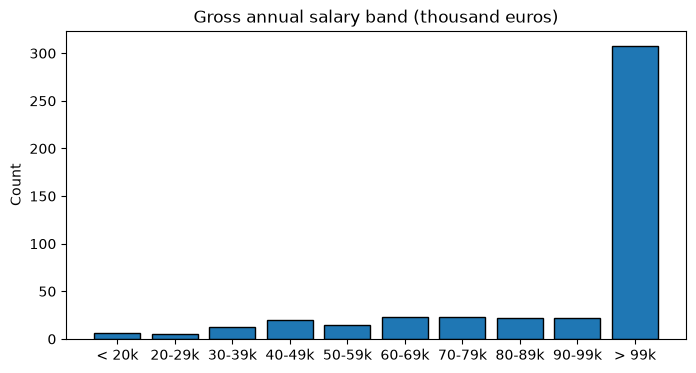

In [34]:
# [Figure 1] Bar chart of the salary band in band order
plt.figure(figsize=(8, 4))
plt.bar(salary_table.index, salary_table['count'], edgecolor='black')
plt.title('Gross annual salary band (thousand euros)')
plt.ylabel('Count')
plt.show()

NOTE: The salary distribution is very unbalanced: 308 respondents (67.4%) are in the top band (> 99k). Each other band holds between 5 and 23 respondents, and only 11 earn less than 30k. How to encode this variable is a decision for Section 2.

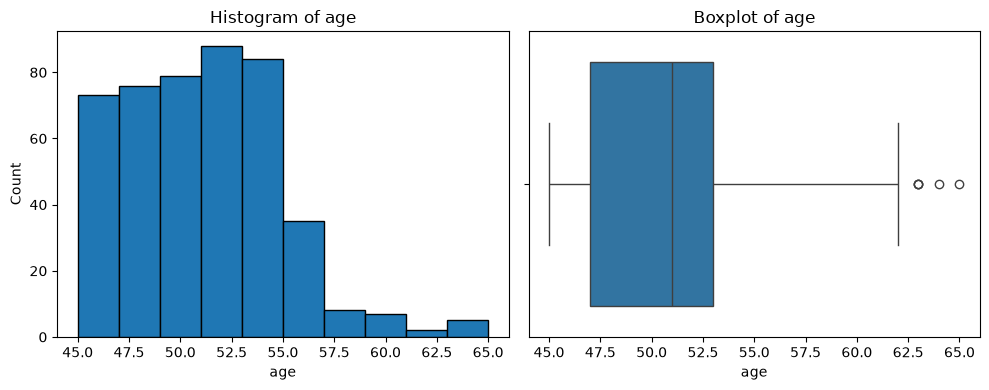

(min            45.0
 25%            47.0
 50%            51.0
 75%            53.0
 max            65.0
 lower fence    38.0
 upper fence    62.0
 Name: age, dtype: float64,
                count  proportion  cumulative
 age                                         
 (44.98, 47.0]    116    0.253829    0.253829
 (47.0, 49.0]      69    0.150985    0.404814
 (49.0, 51.0]      81    0.177243    0.582057
 (51.0, 53.0]      96    0.210066    0.792123
 (53.0, 55.0]      57    0.124726    0.916849
 (55.0, 57.0]      22    0.048140    0.964989
 (57.0, 59.0]       7    0.015317    0.980306
 (59.0, 61.0]       3    0.006565    0.986871
 (61.0, 63.0]       4    0.008753    0.995624
 (63.0, 65.0]       2    0.004376    1.000000)

In [35]:
# Describe age
UniQuant(df, 'age')

NOTE: Age goes from 45 to 65, but half of the respondents are between 47 and 53 (median 51, mean 50.6). The distribution is skewed to the right: there are few executives near retirement age. The 5 respondents older than 62 are above the upper Tukey fence. They are real and plausible ages, not errors.

#### Respondent profile

In [36]:
# [Table 1] Respondent profile: count and percentage of each category, plus age
profile_vars = ['sex', 'job_status', 'education_level', 'degree_type', 'education_place',
                'sector', 'family_status', 'children', 'salary_band']

parts = []
for var in profile_vars:
    counts = df[var].value_counts()
    if var in orders:
        counts = counts.reindex(orders[var])
    part = pd.DataFrame({'Variable': var,
                         'Category': counts.index.astype(str),
                         'n': counts.values,
                         '%': (100 * counts.values / len(df)).round(1)})
    parts.append(part)

age_text = (f"mean {df['age'].mean():.1f} (SD {df['age'].std():.1f}), "
            f"median {df['age'].median():.0f}, range {df['age'].min()}-{df['age'].max()}")
age_row = pd.DataFrame({'Variable': ['age'], 'Category': [age_text], 'n': [len(df)], '%': [np.nan]})

table1 = pd.concat([age_row] + parts, ignore_index=True)
table1

,Variable,Category,n,%
0,age,"mean 50.6 (SD 3.8), median 51, range 45-65",457,NaN
1,sex,Male,282,61.7
2,sex,Female,175,38.3
3,job_status,Employed,390,85.3
4,job_status,Job seeker,67,14.7
5,education_level,Bachelor (3 years),11,2.4
6,education_level,Master (4-5 years),176,38.5
7,education_level,Beyond master (> 5 years),270,59.1
8,degree_type,Business school,367,80.3
9,degree_type,University,35,7.7


NOTE: The typical respondent is a man of about 51, employed, with a business-school degree beyond the master level, living in a couple with children and earning more than 99k a year. Several categories are very small (studied abroad, bachelor, construction, real estate, the lowest salary bands). We will need to deal with them in Section 2.

### 1.2 The 12 employability scores

In [37]:
# [Table 2] Descriptive statistics of the 12 scores
scores = df[score_cols]
table2 = pd.DataFrame({
    'mean': scores.mean(),
    'std': scores.std(),
    'min': scores.min(),
    'median': scores.median(),
    'max': scores.max(),
    'skewness': scores.skew(),
    '% at 7': 100 * (scores == 7).mean(),
    '% at 1': 100 * (scores == 1).mean(),
})
table2 = table2.sort_values('mean', ascending=False).round(2)
table2

,mean,std,min,median,max,skewness,% at 7,% at 1
competence,6.32,0.68,4.00,6.33,7.0,-0.75,36.76,0.00
anticipation,5.68,0.85,3.33,5.67,7.0,-0.39,10.28,0.00
job_search_techniques,5.44,1.12,2.00,5.75,7.0,-0.58,10.50,0.00
value_awareness,5.33,1.10,1.50,5.50,7.0,-0.46,9.19,0.00
flexibility,5.22,1.00,2.67,5.33,7.0,-0.01,7.22,0.00
market_knowledge,5.19,1.24,1.00,5.33,7.0,-0.70,10.94,0.66
versatility,5.09,1.23,1.00,5.00,7.0,-0.44,8.75,0.22
networks,4.96,1.52,1.00,5.20,7.0,-0.55,9.63,0.66
know_how_visibility,4.95,1.16,1.33,5.00,7.0,-0.19,7.00,0.00
training,3.96,1.32,1.29,3.71,7.0,0.40,1.97,0.00


NOTE: The scores are not centred on the middle of the scale (4). Competence is very high (mean 6.32, 36.8% at the maximum, nobody below 4). Anticipation is also high (mean 5.68). At the other end, alternative employment (mean 3.00) and self-efficacy (mean 3.55) are low. Skewness stays between -0.75 and 0.44, so no score is extremely skewed.

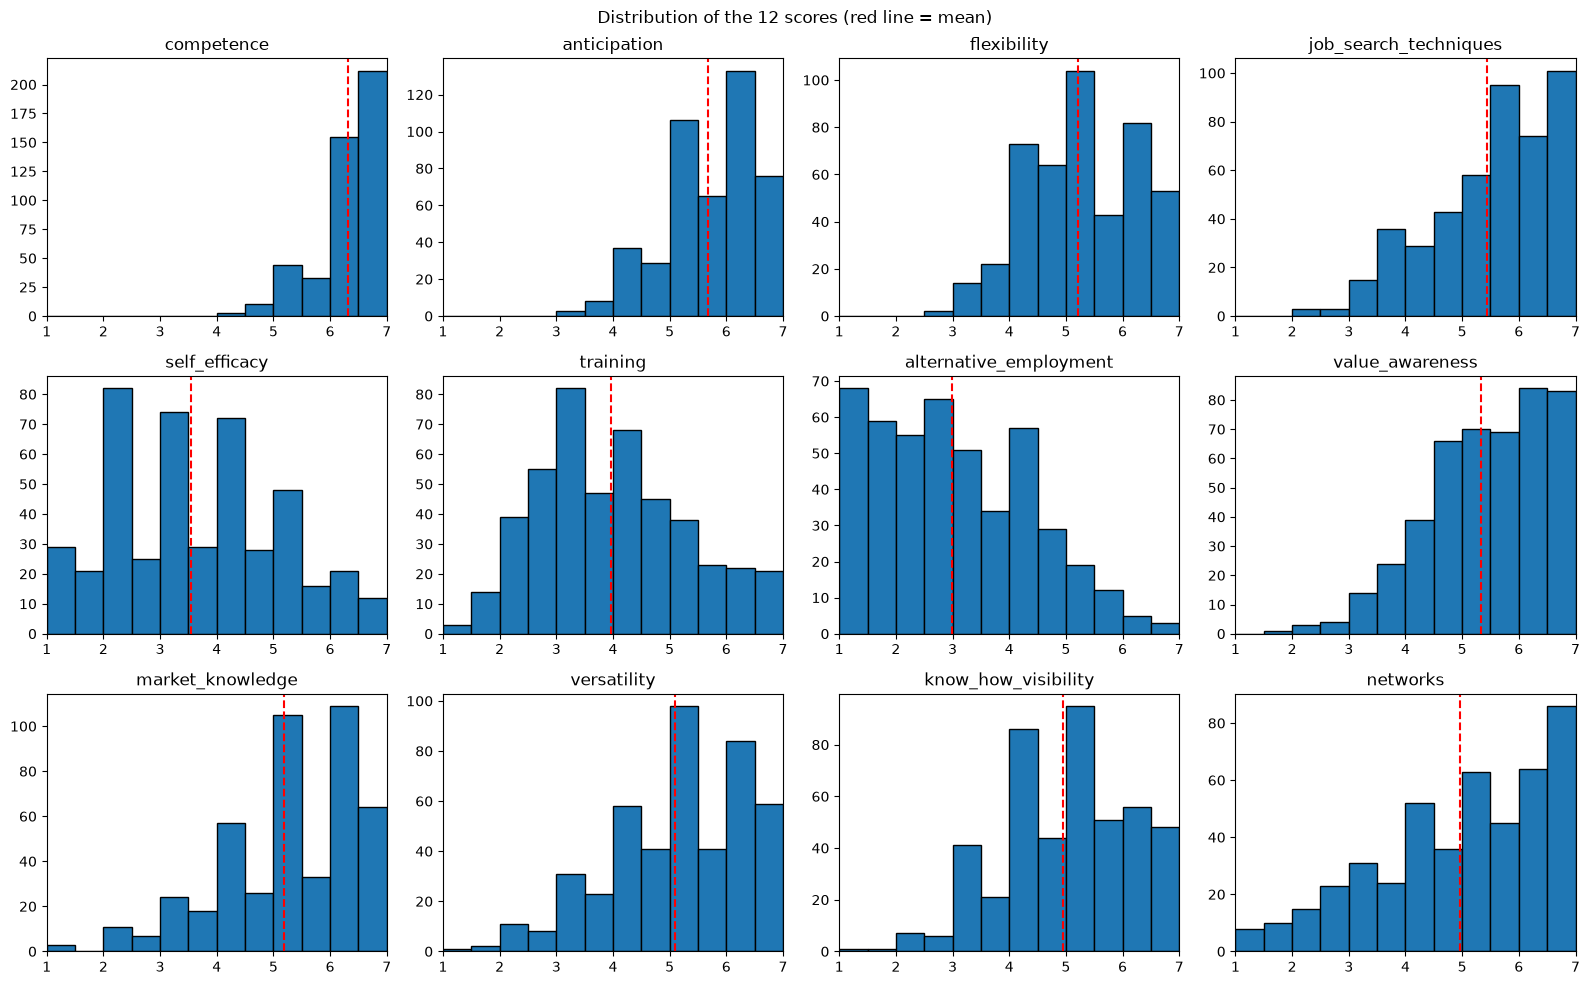

In [38]:
# [Figure 2] Histograms of the 12 scores
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(score_cols):
    axes[i].hist(df[col], bins=12, range=(1, 7), edgecolor='black')
    axes[i].axvline(df[col].mean(), color='red', linestyle='--')
    axes[i].set_title(col)
    axes[i].set_xlim(1, 7)
plt.suptitle('Distribution of the 12 scores (red line = mean)')
plt.tight_layout()
plt.show()

NOTE: Competence is piled up against the right end of the scale, which is a ceiling effect. Alternative employment is piled up on the left. Self-efficacy, training and networks are spread over the whole scale, so they separate respondents well. Most other scores are a little skewed to the left (people tend to agree). The zigzag shape of some histograms is not real: scores built from 3 items can only take steps of 1/3, which do not fit evenly into bins of 0.5.

#### Very high or very low scores

NOTE: Competence is very high for almost everyone (mean 6.32, minimum 4). This is a ceiling effect: experienced executives judge their current job, and it is hard to say you are not competent. Anticipation is also high (mean 5.68) because its questions describe what a good professional should think. Alternative employment is low (mean 3.00) because most questions ask if people have already worked outside an executive job or would accept a step down. Self-efficacy is low on average (mean 3.55) but well spread, which is good for a regression outcome.

#### Correlations between the 12 scores

We use Pearson correlations. The scores are means of 3 to 7 items, so they are close to continuous, and none is strongly skewed. Pearson also measures the same kind of link (linear) as the regression in Part 3.

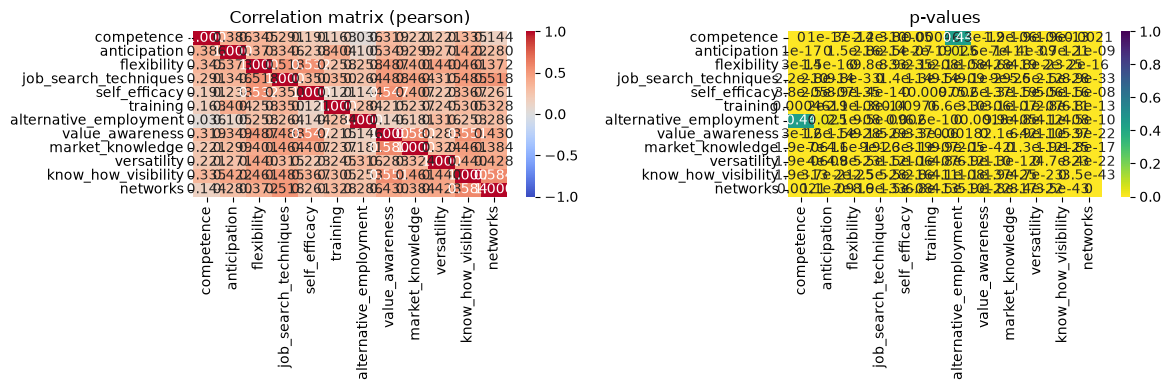

In [39]:
# Pearson correlations of the 12 scores (helper function)
corr, pvals = BivQuant(df[score_cols], method='pearson')

(The 12x12 pairplot produced by BivQuant is removed from the saved output to keep the file small; it is regenerated when the notebook is run.) The plots of BivQuant are hard to read with 12 variables. Below is a simpler version of the same matrix for the report: only the lower half, and the scores placed so that the ones that go together sit next to each other.

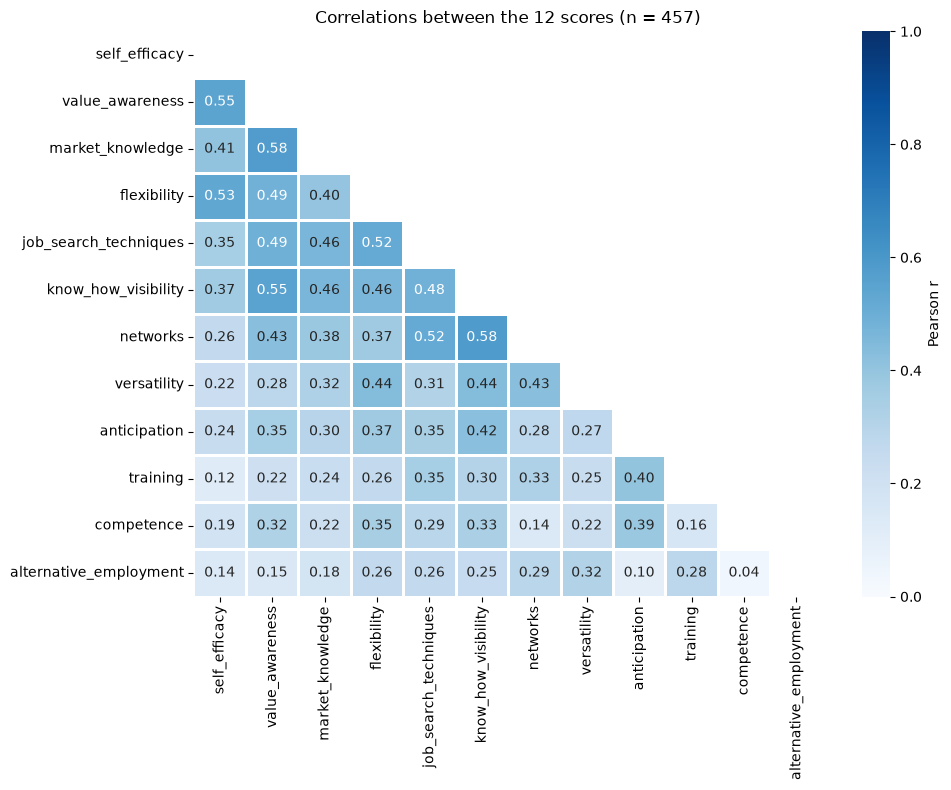

In [40]:
# [Figure 3] Correlation heatmap for the report
order = ['self_efficacy', 'value_awareness', 'market_knowledge', 'flexibility',
         'job_search_techniques', 'know_how_visibility', 'networks', 'versatility',
         'anticipation', 'training', 'competence', 'alternative_employment']
corr_ordered = corr.loc[order, order]
mask = np.triu(np.ones(corr_ordered.shape, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_ordered, mask=mask, annot=True, fmt='.2f', cmap='Blues',
            vmin=0, vmax=1, linewidths=1, linecolor='white',
            cbar_kws={'label': 'Pearson r'})
plt.title('Correlations between the 12 scores (n = 457)')
plt.tight_layout()
plt.show()

In [41]:
# check: largest difference between Spearman and Pearson
spearman = df[score_cols].corr(method='spearman')
(spearman - corr).abs().max().max()

np.float64(0.03761524926368687)

In [42]:
# pairs with |r| > 0.5
strong_pairs = []
for i in range(len(score_cols)):
    for j in range(i + 1, len(score_cols)):
        a = score_cols[i]
        b = score_cols[j]
        if abs(corr.loc[a, b]) > 0.5:
            strong_pairs.append({'score 1': a, 'score 2': b, 'r': corr.loc[a, b]})
strong_pairs = pd.DataFrame(strong_pairs).sort_values('r', ascending=False).round(3)
strong_pairs

,score 1,score 2,r
6,know_how_visibility,networks,0.584
4,value_awareness,market_knowledge,0.580
5,value_awareness,know_how_visibility,0.551
3,self_efficacy,value_awareness,0.547
1,flexibility,self_efficacy,0.532
2,job_search_techniques,networks,0.518
0,flexibility,job_search_techniques,0.518


NOTE: All correlations are positive, and Spearman gives almost the same values (largest difference 0.04). Two groups of scores go together: value awareness, market knowledge, flexibility and self-efficacy on one side, know-how visibility, networks and job search techniques on the other. Seven pairs have r above 0.5 (0.52 to 0.58), five of them between predictors of Part 3, so we check multicollinearity there. Competence, training and alternative employment are only weakly linked to the other scores.

### 1.3 Scores and personal variables

We describe effect sizes with Cohen's (1988) thresholds. Small, medium and large are 0.10, 0.30 and 0.50 for r and Cramér's V, 0.01, 0.06 and 0.14 for η², and 0.2, 0.5 and 0.8 for Cohen's d. For the chi-square test we use Cochran's rule: at most 20% of expected counts below 5. We run about 100 tests in this section, so around 5 small p-values can appear by chance. We therefore look at effect sizes first.

In [43]:
# mark p-values with stars
def stars(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return ''

#### Scores and the quantitative variables (age, children)

In [44]:
corr_personal = pg.pairwise_corr(data=df, columns=[['age', 'children'], score_cols],
                                 method='pearson', padjust=None)
p_col = 'p_unc' if 'p_unc' in corr_personal.columns else 'p-unc'
corr_personal[['X', 'Y', 'r', p_col]].round(3)

,X,Y,r,p_unc
0,age,competence,-0.035,0.458
1,age,anticipation,0.034,0.472
2,age,flexibility,-0.054,0.246
3,age,job_search_techniques,-0.064,0.174
4,age,self_efficacy,-0.177,0.000
5,age,training,-0.009,0.856
6,age,alternative_employment,0.067,0.151
7,age,value_awareness,-0.119,0.011
8,age,market_knowledge,-0.101,0.031
9,age,versatility,-0.003,0.943


In [45]:
# [Table 3] Correlations of the scores with age and children (* p<0.05, ** p<0.01, *** p<0.001)
table3 = pd.DataFrame(index=score_cols, columns=['age', 'children'])
for _, row in corr_personal.iterrows():
    table3.loc[row['Y'], row['X']] = f"{row['r']:.2f}{stars(row[p_col])}"
table3

,age,children
competence,-0.03,-0.01
anticipation,0.03,-0.03
flexibility,-0.05,-0.03
job_search_techniques,-0.06,-0.04
self_efficacy,-0.18***,0.06
training,-0.01,-0.06
alternative_employment,0.07,-0.04
value_awareness,-0.12*,0.01
market_knowledge,-0.10*,-0.01
versatility,-0.00,0.12**


NOTE: Age and the number of children are almost unrelated to the scores. The only effect above the "small" threshold is age with self-efficacy (r = -0.18): older executives are a little less confident that they could find another job. The other significant correlations (age with value awareness, market knowledge and networks; children with versatility) are around 0.10 to 0.12, which is negligible to small.

#### Scores and the categorical variables (one-way ANOVA)

In [46]:
cat_vars = ['sex', 'job_status', 'education_level', 'degree_type', 'sector', 'family_status']
eta2_table = pd.DataFrame(index=score_cols, columns=cat_vars, dtype=float)
p_table = pd.DataFrame(index=score_cols, columns=cat_vars, dtype=float)

for score in score_cols:
    for var in cat_vars:
        anova = pg.anova(dv=score, between=var, data=df, detailed=True)
        p_col = 'p_unc' if 'p_unc' in anova.columns else 'p-unc'
        ssb = anova.loc[0, 'SS']
        ssw = anova.loc[1, 'SS']
        eta2_table.loc[score, var] = ssb / (ssb + ssw)
        p_table.loc[score, var] = anova.loc[0, p_col]

In [47]:
# [Table 4] eta² of each score by each categorical variable (* p<0.05, ** p<0.01, *** p<0.001)
table4 = pd.DataFrame(index=score_cols, columns=cat_vars)
for score in score_cols:
    for var in cat_vars:
        table4.loc[score, var] = f"{eta2_table.loc[score, var]:.3f}{stars(p_table.loc[score, var])}"
table4

,sex,job_status,education_level,degree_type,sector,family_status
competence,0.001,0.000,0.012,0.001,0.010,0.003
anticipation,0.005,0.010*,0.002,0.016,0.024,0.001
flexibility,0.002,0.014*,0.003,0.014,0.027,0.006
job_search_techniques,0.000,0.021**,0.002,0.014,0.047**,0.011
self_efficacy,0.001,0.008,0.000,0.012,0.033,0.003
training,0.025***,0.052***,0.005,0.055***,0.054**,0.010
alternative_employment,0.000,0.014*,0.002,0.012,0.073***,0.008
value_awareness,0.024***,0.005,0.003,0.008,0.016,0.007
market_knowledge,0.002,0.010*,0.004,0.005,0.014,0.002
versatility,0.014*,0.009*,0.009,0.008,0.020,0.003


In [48]:
# 5 strongest pairs
eta2_table.stack().sort_values(ascending=False).head(5).round(3)

networks                sector         0.074
alternative_employment  sector         0.073
training                degree_type    0.055
                        sector         0.054
                        job_status     0.052
dtype: float64

NOTE: All effects are small. Only two pairs reach a medium η² (≥ 0.06): networks by sector (0.074) and alternative employment by sector (0.073). Sector, job status and degree type give the most significant results. Sex, education level and family situation explain almost nothing (η² ≤ 0.025). Training is the score most linked to personal variables: it differs by degree type, sector and job status (η² 0.05 to 0.06).

In [49]:
# [Table 5] Mean of each score for employed people and job seekers
table5 = df.groupby('job_status')[score_cols].mean().T
table5['difference'] = table5['Job seeker'] - table5['Employed']
table5['eta2'] = eta2_table['job_status']
table5.sort_values('difference', ascending=False).round(2)

job_status,Employed,Job seeker,difference,eta2
training,3.83,4.69,0.85,0.05
networks,4.87,5.52,0.65,0.02
know_how_visibility,4.88,5.37,0.49,0.02
job_search_techniques,5.37,5.82,0.46,0.02
alternative_employment,2.93,3.38,0.45,0.01
market_knowledge,5.14,5.49,0.35,0.01
flexibility,5.17,5.51,0.34,0.01
versatility,5.05,5.37,0.33,0.01
anticipation,5.64,5.88,0.24,0.01
value_awareness,5.30,5.51,0.21,0.00


NOTE: Job seekers score higher than employed people on 10 of the 12 dimensions. The largest gaps are training (+0.85), networks (+0.65), know-how visibility (+0.49) and job search techniques (+0.46). Self-efficacy is the exception: job seekers are less confident (3.23 vs 3.61, p = 0.056), even though they are more active. Competence is the same in both groups.

#### Details of the strongest pairs (BivMixte)

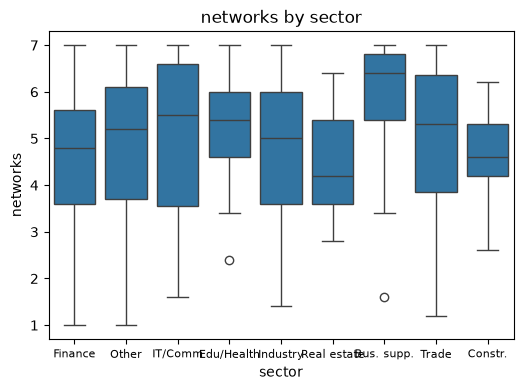

,Source,SS,DF,MS,F,p_unc,np2,eta2,omega2
0,sector,78.600567,8,9.825071,4.490548,0.000029,0.074236,0.074236,0.057585
1,Within,980.199258,448,2.187945,NaN,NaN,NaN,NaN,NaN


In [50]:
# smaller x labels (short sector names)
plt.rcParams['xtick.labelsize'] = 8
anova, pairs = BivMixte(df_plot, dv='networks', group='sector')
plt.rcParams['xtick.labelsize'] = 10
anova

In [51]:
# significant pairs after Bonferroni
p_corr_col = 'p_corr' if 'p_corr' in pairs.columns else 'p-corr'
pairs[pairs[p_corr_col] < 0.05]

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,cohen
2,sector,Bus. supp.,Finance,False,True,6.188152,135.565468,two-sided,6.750151e-09,2.430054e-07,bonferroni,1.637e+06,0.992122
4,sector,Bus. supp.,Industry,False,True,5.182970,134.128960,two-sided,7.842993e-07,2.823478e-05,bonferroni,2.006e+04,0.810965
5,sector,Bus. supp.,Other,False,True,4.871662,131.757116,two-sided,3.121419e-06,1.123711e-04,bonferroni,4954.007,0.808818


NOTE: Executives in business support services use their network much more (mean 5.95) than those in finance & insurance (4.57), industry and "other" (Cohen's d 0.8 to 1.0, large). This sector includes consulting, where working through one's network is part of the job.

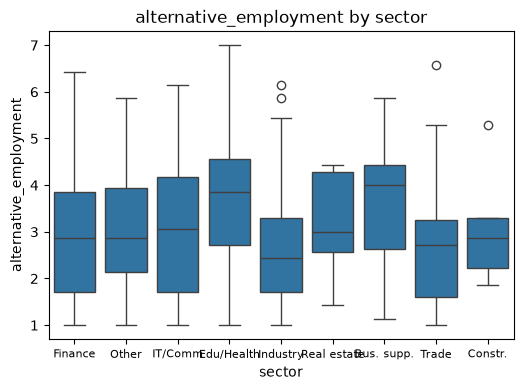

,Source,SS,DF,MS,F,p_unc,np2,eta2,omega2
0,sector,61.294528,8,7.661816,4.41701,0.000037,0.073109,0.073109,0.05644
1,Within,777.107998,448,1.734616,NaN,NaN,NaN,NaN,NaN


In [52]:
# smaller x labels (short sector names)
plt.rcParams['xtick.labelsize'] = 8
anova, pairs = BivMixte(df_plot, dv='alternative_employment', group='sector')
plt.rcParams['xtick.labelsize'] = 10
anova

In [53]:
pairs[pairs[p_corr_col] < 0.05]

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,cohen
2,sector,Bus. supp.,Finance,False,True,3.339367,124.109891,two-sided,0.001109,0.039929,bonferroni,26.441,0.554595
4,sector,Bus. supp.,Industry,False,True,4.908456,107.485687,two-sided,0.000003,0.000118,bonferroni,6458.212,0.831863
7,sector,Bus. supp.,Trade,False,True,4.097717,95.190283,two-sided,0.000088,0.003158,bonferroni,253.116,0.820164


NOTE: Business support services again score highest on alternative employment (3.64, with education, health & social work at 3.73), and industry and trade score lowest (about 2.6). The items include *"I have already worked ... in a non-salaried form of employment (e.g. freelance, consulting)"*, which fits a consulting sector. The differences are medium to large (d 0.55 to 0.83).

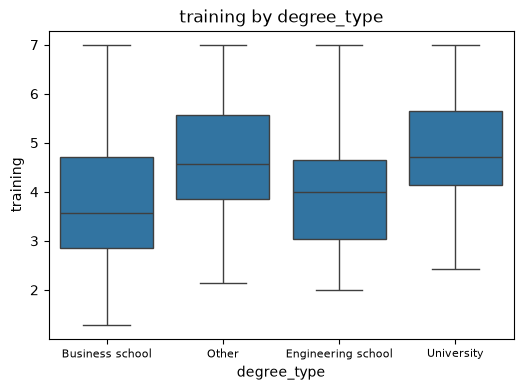

,Source,SS,DF,MS,F,p_unc,np2,eta2,omega2
0,degree_type,43.599050,3,14.533017,8.744587,0.000012,0.054741,0.054741,0.04838
1,Within,752.860803,453,1.661944,NaN,NaN,NaN,NaN,NaN


In [54]:
# smaller x labels
plt.rcParams['xtick.labelsize'] = 8
anova, pairs = BivMixte(df, dv='training', group='degree_type')
plt.rcParams['xtick.labelsize'] = 10
anova

In [55]:
pairs[pairs[p_corr_col] < 0.05]

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,cohen
2,degree_type,Business school,University,False,True,-5.155409,43.782593,two-sided,0.000006,0.000035,bonferroni,3.099e+04,-0.788430
4,degree_type,Engineering school,University,False,True,-2.858689,65.195487,two-sided,0.005706,0.034237,bonferroni,7.278,-0.689755


NOTE: University graduates train more (4.85) than business school graduates (3.83), with a medium effect (d = 0.79). Engineering school graduates are also below university graduates (d = 0.69). University graduates are only 35 people, so this result is less precise than it looks.

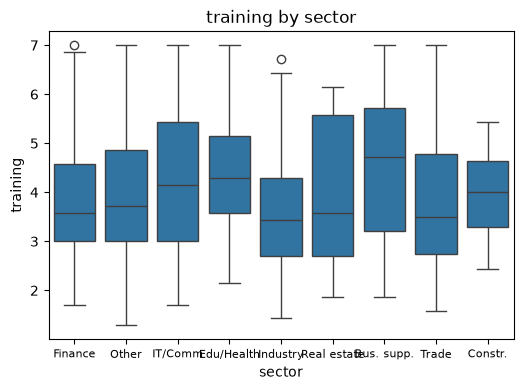

,Source,SS,DF,MS,F,p_unc,np2,eta2,omega2
0,sector,43.155750,8,5.394469,3.208163,0.001482,0.054184,0.054184,0.037216
1,Within,753.304103,448,1.681482,NaN,NaN,NaN,NaN,NaN


In [56]:
# smaller x labels (short sector names)
plt.rcParams['xtick.labelsize'] = 8
anova, pairs = BivMixte(df_plot, dv='training', group='sector')
plt.rcParams['xtick.labelsize'] = 10
anova

In [57]:
pairs[pairs[p_corr_col] < 0.05]

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,p_corr,p_adjust,BF10,cohen
4,sector,Bus. supp.,Industry,False,True,4.183569,94.765138,two-sided,0.000064,0.002307,bonferroni,410.253,0.740911


NOTE: After the Bonferroni correction only one sector pair remains: business support services train more than industry (d = 0.74). The other sector differences in training are too small to be sure with our group sizes.

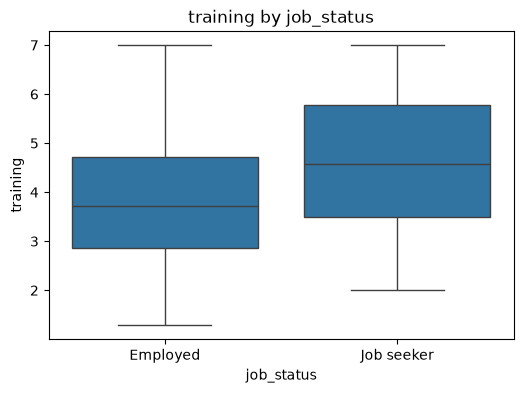

,Source,SS,DF,MS,F,p_unc,np2,eta2,omega2
0,job_status,41.502281,1,41.502281,25.012714,8.146988e-07,0.052108,0.052108,0.049921
1,Within,754.957572,455,1.659247,NaN,NaN,NaN,NaN,NaN


In [58]:
anova, pairs = BivMixte(df, dv='training', group='job_status')
anova

In [59]:
pairs

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p_unc,BF10,cohen
0,job_status,Employed,Job seeker,False,True,-4.63513,85.27835,two-sided,0.000013,3194.565,-0.661407


NOTE: Job seekers have a clearly higher training score (4.69 vs 3.83, p < 0.001, Cohen's d = 0.66, medium). Several training items are about plans (*"I plan to follow a training programme in the near future"*), so job seekers may score high because they are preparing to change jobs. We come back to this question of direction (cause or consequence) in Part 4.

#### job_status and the other categorical variables (chi-square)

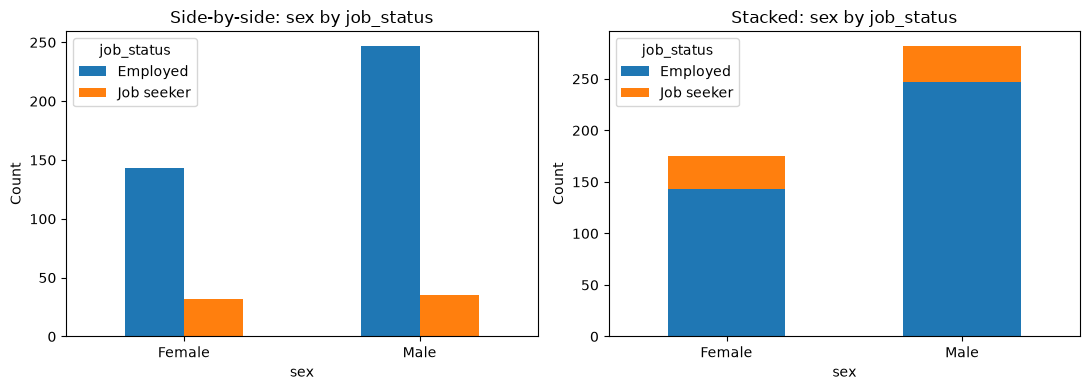

job_status,Employed,Job seeker
sex,,
Female,143,32
Male,247,35


In [60]:
res_sex = BivCat(df, 'job_status', 'sex')
res_sex['observed']

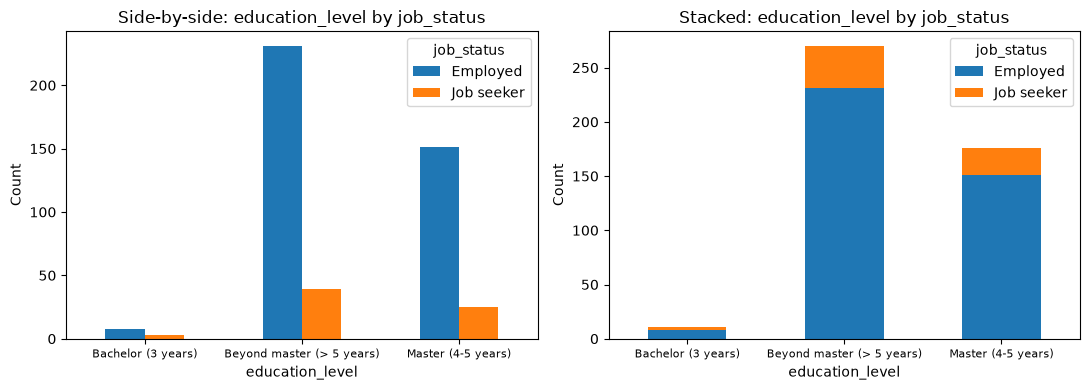

job_status,Employed,Job seeker
education_level,,
Bachelor (3 years),8,3
Beyond master (> 5 years),231,39
Master (4-5 years),151,25


In [61]:
# smaller x labels (long names)
plt.rcParams['xtick.labelsize'] = 8
res_edu_level = BivCat(df, 'job_status', 'education_level')
plt.rcParams['xtick.labelsize'] = 10
res_edu_level['observed']

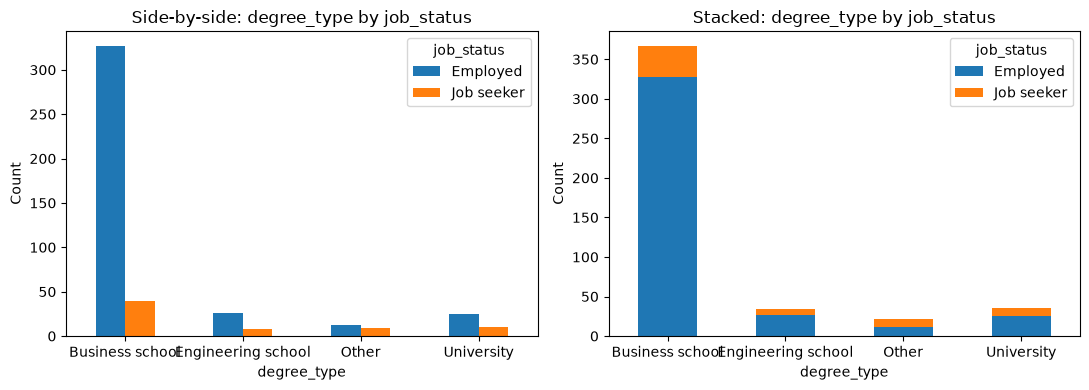

job_status,Employed,Job seeker
degree_type,,
Business school,327,40
Engineering school,26,8
Other,12,9
University,25,10


In [62]:
res_degree = BivCat(df, 'job_status', 'degree_type')
res_degree['observed']

In [63]:
res_degree['standardized_residuals'].round(2)

job_status,Employed,Job seeker
degree_type,,
Business school,4.59,-4.59
Engineering school,-1.52,1.52
Other,-3.74,3.74
University,-2.42,2.42


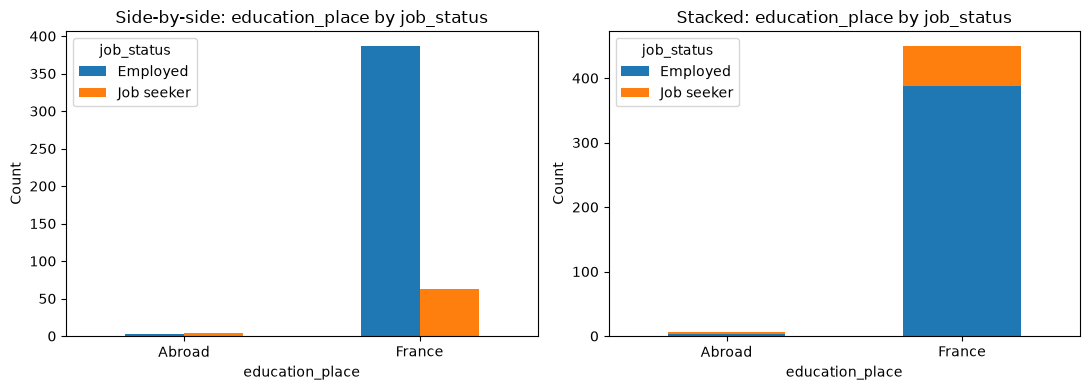

job_status,Employed,Job seeker
education_place,,
Abroad,3,4
France,387,63


In [64]:
res_edu_place = BivCat(df, 'job_status', 'education_place')
res_edu_place['observed']

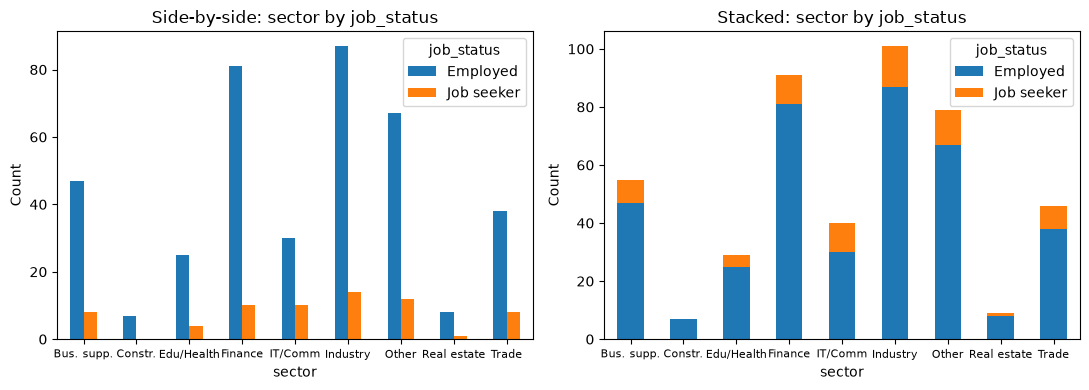

job_status,Employed,Job seeker
sector,,
Bus. supp.,47,8
Constr.,7,0
Edu/Health,25,4
Finance,81,10
IT/Comm,30,10
Industry,87,14
Other,67,12
Real estate,8,1
Trade,38,8


In [65]:
# short sector names, smaller x labels
plt.rcParams['xtick.labelsize'] = 8
res_sector = BivCat(df_plot, 'job_status', 'sector')
plt.rcParams['xtick.labelsize'] = 10
res_sector['observed']

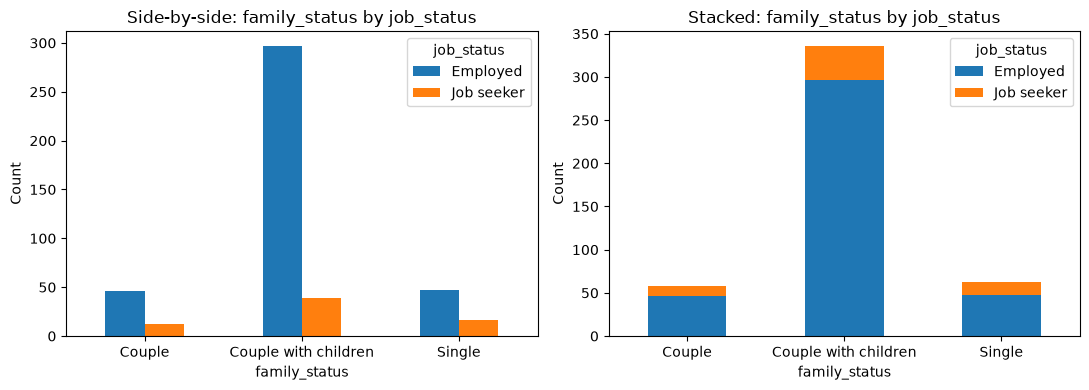

job_status,Employed,Job seeker
family_status,,
Couple,46,12
Couple with children,297,39
Single,47,16


In [66]:
res_family = BivCat(df, 'job_status', 'family_status')
res_family['observed']

In [67]:
res_family['standardized_residuals'].round(2)

job_status,Employed,Job seeker
family_status,,
Couple,-1.39,1.39
Couple with children,3.08,-3.08
Single,-2.59,2.59


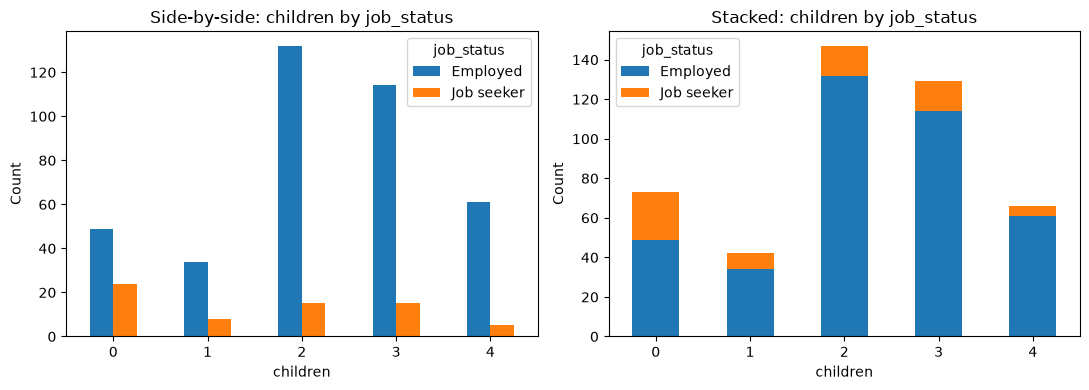

job_status,Employed,Job seeker
children,,
0,49,24
1,34,8
2,132,15
3,114,15
4,61,5


In [68]:
res_children = BivCat(df, 'job_status', 'children')
res_children['observed']

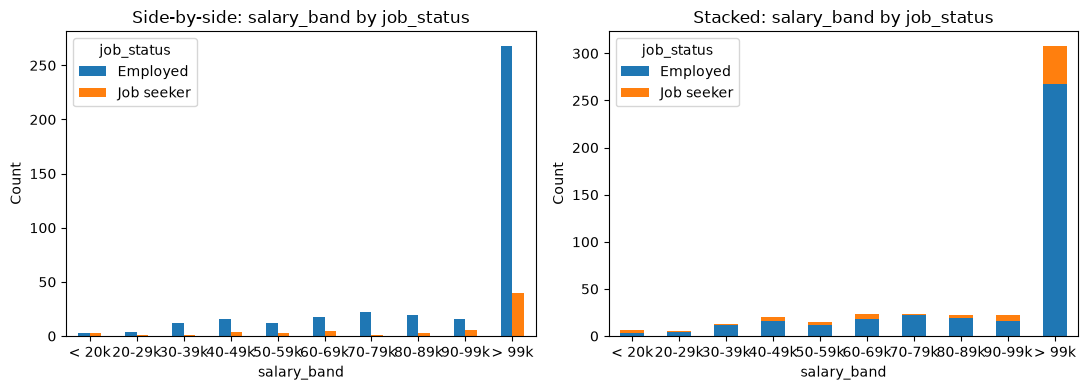

job_status,Employed,Job seeker
salary_band,,
< 20k,3,3
20-29k,4,1
30-39k,12,1
40-49k,16,4
50-59k,12,3
60-69k,18,5
70-79k,22,1
80-89k,19,3
90-99k,16,6


In [69]:
# salary bands in band order for the chart
df_salary = df.copy()
df_salary['salary_band'] = pd.Categorical(df_salary['salary_band'], categories=orders['salary_band'], ordered=True)
res_salary = BivCat(df_salary, 'job_status', 'salary_band')
res_salary['observed']

In [70]:
# [Table 6] Chi-square tests: job_status by each categorical variable
results = {'sex': res_sex, 'education_level': res_edu_level, 'degree_type': res_degree,
           'education_place': res_edu_place, 'sector': res_sector,
           'family_status': res_family, 'children': res_children, 'salary_band': res_salary}
rows = []
for var, res in results.items():
    job_seekers = pd.crosstab(df[var], df['job_status'], normalize='index')['Job seeker'] * 100
    rows.append({'variable': var,
                 'chi2': res['chi2'],
                 'dof': res['dof'],
                 'p_value': res['p_value'],
                 'cramers_v': res['cramers_v'],
                 '% expected < 5': 100 * res['share_expected_below_5'],
                 'valid (<= 20%)': res['share_expected_below_5'] <= 0.20,
                 '% job seekers: lowest-highest': f'{job_seekers.min():.0f}-{job_seekers.max():.0f}'})
table6 = pd.DataFrame(rows).sort_values('cramers_v', ascending=False).round(3)
table6

,variable,chi2,dof,p_value,cramers_v,% expected < 5,valid (<= 20%),% job seekers: lowest-highest
6,children,25.937,4,0.000,0.238,0.000,True,8-33
2,degree_type,25.046,3,0.000,0.234,25.000,False,11-43
7,salary_band,13.786,9,0.130,0.174,50.000,False,4-50
3,education_place,10.254,1,0.001,0.150,25.000,False,14-57
5,family_status,9.993,2,0.007,0.148,0.000,True,12-25
4,sector,6.053,8,0.641,0.115,16.667,True,0-25
0,sex,2.978,1,0.084,0.081,0.000,True,12-18
1,education_level,1.438,2,0.487,0.056,16.667,True,14-27


NOTE: The number of children has the strongest link with job status (V = 0.24, valid): 33% of the people without dependent children are job seekers, against 8% of those with four or more. Degree type (V = 0.23), education place (V = 0.15) and family situation (V = 0.15) are also linked, but only family situation passes the validity rule: singles (25.4%) and couples without children (20.7%) are more often job seekers than couples with children (11.6%). The tests for degree type and education place are not valid because some groups are very small (degree type is tested again in Part 2). Sex, education level, sector and salary band show no clear link.

## 2. Preparing the data

We keep `df` unchanged and build a new dataframe, `df_model`, for the models of Parts 3 and 4. The respondent number is only an ID, so it is not used.

In [71]:
df_model = df.drop(columns=['respondent']).copy()
df_model.shape

(457, 22)

### 2.1 Rare categories

In [72]:
# sector: merge the two smallest sectors with the closest one
sector_merge = {'Construction': 'Industry',
                'Real estate': 'Finance & insurance'}
df_model['sector'] = df_model['sector'].replace(sector_merge)
df_model['sector'].value_counts()

sector
Industry                                  108
Finance & insurance                       100
Other                                      79
Business support services                  55
Trade, transport, hotels & restaurants     46
Information & communication                40
Education, health & social work            29
Name: count, dtype: int64

NOTE: Construction (7 people, no job seeker at all) is merged with industry: both are the secondary sector. Real estate (9 people) is merged with finance & insurance, as is often done ("finance, insurance and real estate"). Their networks scores were close (4.63 vs 4.84 and 4.49 vs 4.57). We now have 7 sectors, the smallest with 29 people.

In [73]:
# education level: two groups
education_merge = {'Bachelor (3 years)': 'Master or below',
                   'Master (4-5 years)': 'Master or below',
                   'Beyond master (> 5 years)': 'Beyond master'}
df_model['education_level'] = df_model['education_level'].replace(education_merge)
df_model['education_level'].value_counts()

education_level
Beyond master      270
Master or below    187
Name: count, dtype: int64

NOTE: Only 11 people have a bachelor, too few for their own category. We merge them with the masters, which keeps the natural order: "Master or below" (187) and "Beyond master" (270). Education level was not linked to any score or to job status in Part 1, so we lose very little.

In [74]:
# degree type: business school or not
degree_merge = {'Engineering school': 'Other degree',
                'University': 'Other degree',
                'Other': 'Other degree'}
df_model['degree_type'] = df_model['degree_type'].replace(degree_merge)
df_model['degree_type'].value_counts()

degree_type
Business school    367
Other degree        90
Name: count, dtype: int64

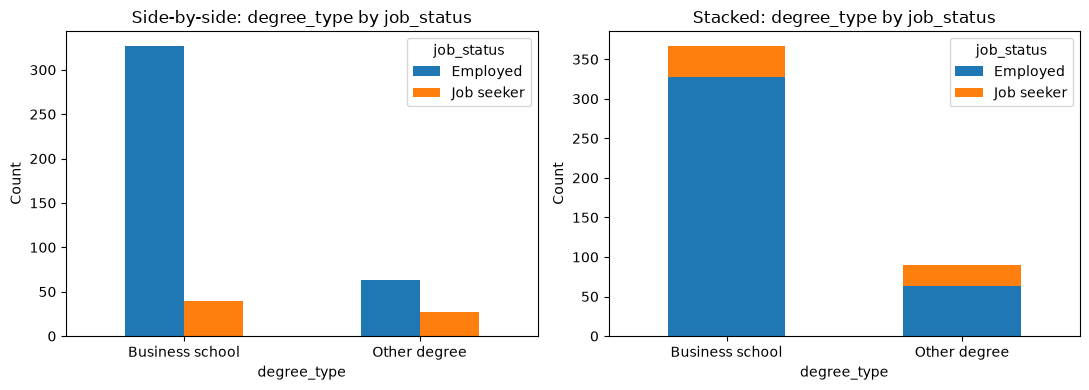

job_status,Employed,Job seeker
degree_type,,
Business school,327,40
Other degree,63,27


In [75]:
# test again with job_status (it was not valid with 4 categories)
res_degree_2 = BivCat(df_model, 'job_status', 'degree_type')
res_degree_2['observed']

In [76]:
print('chi2 =', round(res_degree_2['chi2'], 2), '| p =', round(res_degree_2['p_value'], 6),
      '| V =', round(res_degree_2['cramers_v'], 3),
      '| share of expected counts < 5 =', res_degree_2['share_expected_below_5'])

chi2 = 21.08 | p = 4e-06 | V = 0.215 | share of expected counts < 5 = 0.0


NOTE: Most respondents (367) come from a business school. The other 90 (engineering school, university, other) are grouped together. With two groups the chi-square test is now valid (no expected count below 5). The link with job status stays: 30.0% of the "other degree" group are job seekers, against 10.9% of business school graduates (V = 0.22, small).

### 2.2 Salary

In [77]:
# salary: three groups
salary_groups = {'< 20k': '< 60k', '20-29k': '< 60k', '30-39k': '< 60k', '40-49k': '< 60k', '50-59k': '< 60k',
                 '60-69k': '60-99k', '70-79k': '60-99k', '80-89k': '60-99k', '90-99k': '60-99k',
                 '> 99k': '> 99k'}
df_model['salary_group'] = df_model['salary_band'].replace(salary_groups)
df_model = df_model.drop(columns=['salary_band'])
df_model['salary_group'].value_counts()

salary_group
> 99k     308
60-99k     90
< 60k      59
Name: count, dtype: int64

In [78]:
# self-efficacy and share of job seekers in each salary group
df_model.groupby('salary_group').agg(n=('self_efficacy', 'size'),
                                     mean_self_efficacy=('self_efficacy', 'mean'),
                                     share_job_seekers=('job_status', lambda s: (s == 'Job seeker').mean())).round(2)

,n,mean_self_efficacy,share_job_seekers
salary_group,,,
60-99k,90,3.18,0.17
< 60k,59,3.53,0.20
> 99k,308,3.66,0.13


NOTE: Two thirds of the respondents (308) are in the top band, and the other bands hold only 5 to 23 people each. We group the bands into three groups: < 60k (59), 60-99k (90) and > 99k (308), and code them as dummies with > 99k as reference. Ordinal codes 1 to 10 would assume equal steps between bands and a straight-line effect, but the top band is open (> 99k), and the pattern is not a straight line: mean self-efficacy is 3.53, 3.18 and 3.66 in the three groups. Ten separate dummies would need 9 coefficients estimated on very small groups.

### 2.3 Almost-constant variables

In [79]:
# share of the most frequent category
for var in ['sex', 'education_level', 'degree_type', 'education_place', 'sector', 'family_status', 'salary_group']:
    share = df_model[var].value_counts(normalize=True).iloc[0]
    print(var, round(100 * share, 1), '%')

sex 61.7 %
education_level 59.1 %
degree_type 80.3 %
education_place 98.5 %
sector 23.6 %
family_status 73.5 %
salary_group 67.4 %


In [80]:
df_model = df_model.drop(columns=['education_place'])

NOTE: education_place is almost constant: 450 respondents (98.5%) got their degree in France and only 7 abroad. A dummy based on 7 people would give a very unstable coefficient, so we drop it, since variables without variability carry no information. (4 of these 7 people are job seekers, but 7 people are too few to conclude anything.) No other variable has more than 81% in one category.

### 2.4 Family situation and children

In [81]:
# couple: 1 = lives in a couple (with or without children), 0 = single
df_model['couple'] = (df_model['family_status'] != 'Single').astype(int)
df_model = df_model.drop(columns=['family_status'])
df_model['couple'].value_counts()

couple
1    394
0     63
Name: count, dtype: int64

In [82]:
pd.crosstab(df_model['couple'], df_model['children'])

children,0,1,2,3,4
couple,,,,,
0,37,8,12,3,3
1,36,34,135,126,63


NOTE: family_status mixed two pieces of information: living in a couple, and having children. The second one is already in `children`, and the two sometimes disagreed (27 "Couple" respondents report dependent children). We keep each piece of information once: `couple` (from family_status) and `children` (the number of dependent children, 0 to 4). This removes the contradiction. We keep children as a number (0 to 4), as in the codebook.

### 2.5 Encoding

In [83]:
# outcome of Part 4: 1 = job seeker, 0 = employed
df_model['job_seeker'] = (df_model['job_status'] == 'Job seeker').astype(int)
df_model = df_model.drop(columns=['job_status'])
df_model['job_seeker'].value_counts()

job_seeker
0    390
1     67
Name: count, dtype: int64

In [84]:
# dummies for the categorical variables
cat_model = ['sex', 'sector', 'education_level', 'degree_type', 'salary_group']
df_model = pd.get_dummies(df_model, columns=cat_model, dtype=float)
df_model.columns.tolist()

['competence',
 'anticipation',
 'flexibility',
 'job_search_techniques',
 'self_efficacy',
 'training',
 'alternative_employment',
 'value_awareness',
 'market_knowledge',
 'versatility',
 'know_how_visibility',
 'networks',
 'age',
 'children',
 'couple',
 'job_seeker',
 'sex_Female',
 'sex_Male',
 'sector_Business support services',
 'sector_Education, health & social work',
 'sector_Finance & insurance',
 'sector_Industry',
 'sector_Information & communication',
 'sector_Other',
 'sector_Trade, transport, hotels & restaurants',
 'education_level_Beyond master',
 'education_level_Master or below',
 'degree_type_Business school',
 'degree_type_Other degree',
 'salary_group_60-99k',
 'salary_group_< 60k',
 'salary_group_> 99k']

In [85]:
# drop one dummy per variable: the reference category
reference = ['sex_Male',
             'sector_Industry',
             'education_level_Master or below',
             'degree_type_Business school',
             'salary_group_> 99k']
df_model = df_model.drop(columns=reference)

NOTE: One dummy per variable is dropped and becomes the reference, to avoid the dummy variable trap. We choose the references ourselves instead of drop_first, which uses alphabetical order: Male, Industry, Master or below, Business school and > 99k. For couple and job_seeker, 0 means single and employed.

### 2.6 Final check

In [86]:
df_model.shape

(457, 27)

In [87]:
df_model.columns.tolist()

['competence',
 'anticipation',
 'flexibility',
 'job_search_techniques',
 'self_efficacy',
 'training',
 'alternative_employment',
 'value_awareness',
 'market_knowledge',
 'versatility',
 'know_how_visibility',
 'networks',
 'age',
 'children',
 'couple',
 'job_seeker',
 'sex_Female',
 'sector_Business support services',
 'sector_Education, health & social work',
 'sector_Finance & insurance',
 'sector_Information & communication',
 'sector_Other',
 'sector_Trade, transport, hotels & restaurants',
 'education_level_Beyond master',
 'degree_type_Other degree',
 'salary_group_60-99k',
 'salary_group_< 60k']

In [88]:
df_model.isna().sum().sum()

np.int64(0)

In [89]:
df_model.dtypes.value_counts()

float64    23
int64       4
Name: count, dtype: int64

NOTE: df_model has 457 rows and 27 columns, all numeric, with no missing values: the 12 scores, age, children, couple, job_seeker and 11 dummies (sex 1, sector 6, education level 1, degree type 1, salary 2). `df` is unchanged.

In [90]:
# [Table 7] Data preparation decisions
prep = [
    ['duplicated rows', '3 copies dropped (n = 457)', 'identical on all 22 variables'],
    ['sector', 'Construction -> Industry, Real estate -> Finance & insurance (7 sectors)', '7 and 9 people, Construction had no job seeker'],
    ['education_level', 'Bachelor + Master -> Master or below', 'only 11 bachelors'],
    ['degree_type', 'Business school vs other degree', '80% business school, chi-square becomes valid'],
    ['salary_band', '3 groups as dummies (< 60k, 60-99k, > 99k)', '67% in the open top band, pattern not linear'],
    ['education_place', 'dropped', '98.5% France, almost constant'],
    ['family_status, children', 'couple (0/1) + children (0-4)', 'same information counted once'],
    ['references', 'Male, Industry, Master or below, Business school, > 99k', 'largest or most natural group'],
    ['job_status', 'job_seeker: 1 = job seeker, 0 = employed', 'outcome of Part 4'],
]
table7 = pd.DataFrame(prep, columns=['variable', 'decision', 'reason'])
table7

,variable,decision,reason
0,duplicated rows,3 copies dropped (n = 457),identical on all 22 variables
1,sector,"Construction -> Industry, Real estate -> Finan...","7 and 9 people, Construction had no job seeker"
2,education_level,Bachelor + Master -> Master or below,only 11 bachelors
3,degree_type,Business school vs other degree,"80% business school, chi-square becomes valid"
4,salary_band,"3 groups as dummies (< 60k, 60-99k, > 99k)","67% in the open top band, pattern not linear"
5,education_place,dropped,"98.5% France, almost constant"
6,"family_status, children",couple (0/1) + children (0-4),same information counted once
7,references,"Male, Industry, Master or below, Business scho...",largest or most natural group
8,job_status,"job_seeker: 1 = job seeker, 0 = employed",outcome of Part 4


## 3. What drives professional self-efficacy?

The outcome is self_efficacy, the confidence in being able to find another job (for example: "I could easily obtain a job similar to mine in different types of organisations").

### 3.1 Choice of predictors

In [91]:
score_predictors = ['competence', 'anticipation', 'flexibility', 'job_search_techniques', 'training',
                    'alternative_employment', 'value_awareness', 'market_knowledge', 'versatility',
                    'know_how_visibility', 'networks']
personal_predictors = ['age', 'children', 'couple', 'sex_Female',
                       'sector_Business support services', 'sector_Education, health & social work',
                       'sector_Finance & insurance', 'sector_Information & communication',
                       'sector_Other', 'sector_Trade, transport, hotels & restaurants',
                       'education_level_Beyond master', 'degree_type_Other degree',
                       'salary_group_60-99k', 'salary_group_< 60k']
predictors_lr = score_predictors + personal_predictors
len(predictors_lr)

25

In [92]:
# [Table 8] VIF of the proposed predictors
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(df_model[predictors_lr])
vif = []
for i in range(1, X_vif.shape[1]):
    vif.append(variance_inflation_factor(X_vif.values, i))
table8 = pd.DataFrame({'VIF': vif}, index=predictors_lr).sort_values('VIF', ascending=False).round(2)
table8

,VIF
know_how_visibility,2.23
value_awareness,2.12
networks,2.06
job_search_techniques,1.93
flexibility,1.84
market_knowledge,1.73
versatility,1.64
sector_Finance & insurance,1.62
sector_Other,1.59
anticipation,1.56


NOTE: The VIF says how much the variance of a coefficient grows because the predictor is correlated with the other predictors. A VIF above 5 or 10 is usually seen as a problem (James et al., ISLP, section 3.3.3). Here all VIFs are between 1.10 and 2.23. The highest are know_how_visibility (2.23), value_awareness (2.12) and networks (2.06), the scores flagged in Part 1. So multicollinearity is not a serious problem, but these correlated scores still share part of their effect, which makes ranking them harder.

### 3.2 Linear regression

In [93]:
X_lr = sm.add_constant(df_model[predictors_lr])
y_lr = df_model['self_efficacy']
ols_model = sm.OLS(y_lr, X_lr).fit()

In [94]:
# full output
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:          self_efficacy   R-squared:                       0.448
Model:                            OLS   Adj. R-squared:                  0.416
Method:                 Least Squares   F-statistic:                     14.00
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.64e-41
Time:                        11:16:55   Log-Likelihood:                -688.59
No. Observations:                 457   AIC:                             1429.
Df Residuals:                     431   BIC:                             1536.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
                                                    coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [95]:
# [Table 9] Coefficients of the linear regression with 95% confidence intervals
ci_lr = ols_model.conf_int()
table9 = pd.DataFrame({'coef': ols_model.params,
                       'ci_low': ci_lr[0],
                       'ci_high': ci_lr[1],
                       'p_value': ols_model.pvalues})
table9.round(3)

,coef,ci_low,ci_high,p_value
const,1.241,-0.709,3.192,0.212
competence,-0.118,-0.296,0.060,0.193
anticipation,0.012,-0.140,0.164,0.879
flexibility,0.551,0.410,0.691,0.000
job_search_techniques,-0.012,-0.140,0.116,0.850
training,-0.035,-0.132,0.061,0.474
alternative_employment,0.036,-0.053,0.125,0.422
value_awareness,0.449,0.312,0.587,0.000
market_knowledge,0.107,-0.003,0.217,0.057
versatility,-0.078,-0.186,0.029,0.153


NOTE: R² = 0.448: the model explains about 45% of the differences in self-efficacy between respondents. The other 55% come from things we do not measure. Adjusted R² (0.416) is lower because it takes away the small gain that any extra predictor gives by chance. With 25 predictors this penalty is about 3 points. The warning about the condition number comes from the different scales of the variables (age is around 50, dummies are 0 or 1), not from collinearity: all VIFs are below 2.3 (Table 8).

NOTE: Six predictors are significant at 5%. One more point of flexibility goes with 0.55 more points of self-efficacy, other things equal. One more point of value awareness goes with 0.45 more points. Each extra year of age goes with 0.04 fewer points (about 0.4 points over 10 years). Executives in education, health & social work score 0.55 points higher than those in industry. Compared with people earning more than 99k, those earning 60-99k score 0.35 points lower and those under 60k 0.42 points lower. Market knowledge is just above the 5% threshold (p = 0.057).

### 3.3 Standardised coefficients

In [96]:
# z-scores
lr_vars = predictors_lr + ['self_efficacy']
df_std = (df_model[lr_vars] - df_model[lr_vars].mean()) / df_model[lr_vars].std()
ols_std = sm.OLS(df_std['self_efficacy'], sm.add_constant(df_std[predictors_lr])).fit()

In [97]:
std_coefs = pd.DataFrame({'std_coef': ols_std.params,
                          'ci_low': ols_std.conf_int()[0],
                          'ci_high': ols_std.conf_int()[1],
                          'p_value': ols_std.pvalues}).drop('const')
std_coefs = std_coefs.sort_values('std_coef')
std_coefs.round(3)

,std_coef,ci_low,ci_high,p_value
age,-0.107,-0.182,-0.031,0.006
salary_group_60-99k,-0.096,-0.176,-0.015,0.020
salary_group_< 60k,-0.095,-0.182,-0.008,0.033
networks,-0.082,-0.183,0.019,0.112
versatility,-0.065,-0.155,0.024,0.153
"sector_Trade, transport, hotels & restaurants",-0.060,-0.142,0.021,0.146
sector_Information & communication,-0.060,-0.142,0.022,0.151
education_level_Beyond master,-0.058,-0.132,0.015,0.121
competence,-0.054,-0.136,0.028,0.193
sector_Finance & insurance,-0.044,-0.133,0.046,0.339


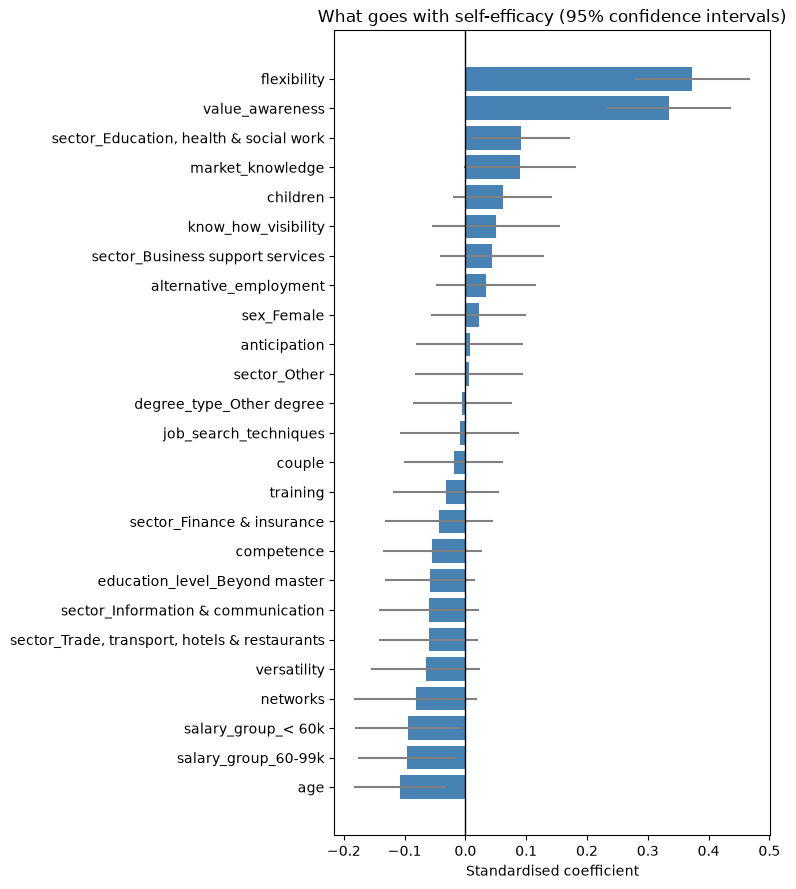

In [98]:
# [Figure 4] Standardised coefficients with 95% confidence intervals
error_low = std_coefs['std_coef'] - std_coefs['ci_low']
error_high = std_coefs['ci_high'] - std_coefs['std_coef']
plt.figure(figsize=(8, 9))
plt.barh(std_coefs.index, std_coefs['std_coef'], xerr=[error_low, error_high], color='steelblue', ecolor='grey')
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Standardised coefficient')
plt.title('What goes with self-efficacy (95% confidence intervals)')
plt.tight_layout()
plt.show()

NOTE: Raw coefficients cannot be compared directly, because the predictors use different units (a score point, a year of age, a 0/1 dummy). After turning every variable into z-scores, a coefficient means "one standard deviation more of X goes with b standard deviations more of self-efficacy", so the sizes can be compared. Flexibility (0.37) and value awareness (0.34) are far ahead of all other predictors. Age (-0.11) and the two lower salary groups (about -0.10) come next, and everything else is close to zero.

### 3.4 Checking the assumptions

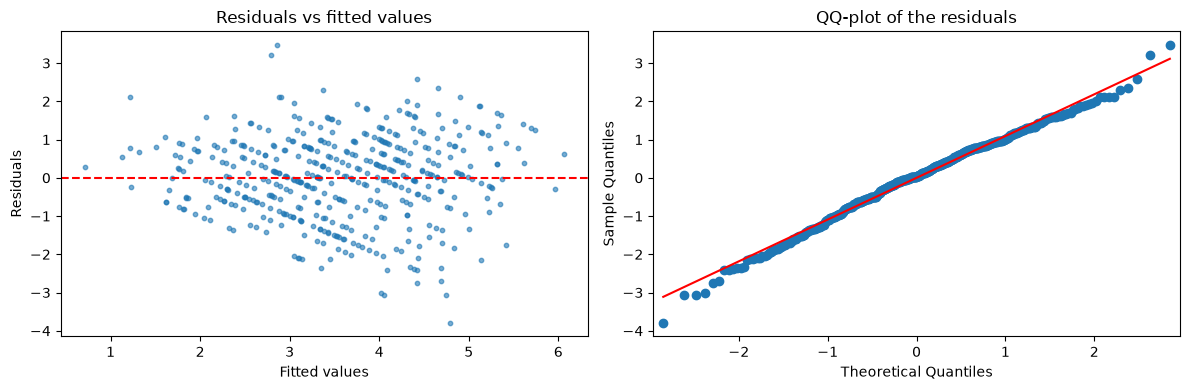

In [99]:
# [Figure 5] Residuals vs fitted values, and QQ-plot of the residuals
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ols_model.fittedvalues, ols_model.resid, s=10, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs fitted values')
sm.qqplot(ols_model.resid, line='s', ax=axes[1])
axes[1].set_title('QQ-plot of the residuals')
plt.tight_layout()
plt.show()

NOTE: The residuals have no clear pattern against the fitted values, and their spread is about the same everywhere, so linearity and constant variance look acceptable. The diagonal lines come from self-efficacy itself, which only takes steps of 1/3. The QQ-plot is close to the straight line, with a slightly longer left tail (a few people much less confident than predicted). With 457 respondents this small departure from normality is not a problem for the tests.

### 3.5 Limits of ranking the predictors

In [100]:
# [Table 10] Correlation with self_efficacy alone vs standardised coefficient in the model
table10 = pd.DataFrame({'r alone': df_model[score_predictors].corrwith(df_model['self_efficacy']),
                       'std coef in model': ols_std.params[score_predictors],
                       'ci_low': ols_std.conf_int().loc[score_predictors, 0],
                       'ci_high': ols_std.conf_int().loc[score_predictors, 1],
                       'VIF': table8.loc[score_predictors, 'VIF']})
table10.sort_values('r alone', ascending=False).round(2)

,r alone,std coef in model,ci_low,ci_high,VIF
value_awareness,0.55,0.33,0.23,0.44,2.12
flexibility,0.53,0.37,0.28,0.47,1.84
market_knowledge,0.41,0.09,-0.00,0.18,1.73
know_how_visibility,0.37,0.05,-0.06,0.15,2.23
job_search_techniques,0.35,-0.01,-0.11,0.09,1.93
networks,0.26,-0.08,-0.18,0.02,2.06
anticipation,0.24,0.01,-0.08,0.09,1.56
versatility,0.22,-0.07,-0.16,0.02,1.64
competence,0.19,-0.05,-0.14,0.03,1.35
alternative_employment,0.14,0.03,-0.05,0.12,1.36


NOTE: The order of the standardised coefficients is not a firm ranking. The scores are correlated (r up to 0.58, Figure 3), so they share part of the same information, and the model gives this shared part to only one of them. This is why five scores that are positively linked to self-efficacy on their own (job search techniques r = 0.35, networks 0.26, versatility 0.22, competence 0.19, training 0.12) get a negative coefficient in the model. The VIFs are low (≤ 2.23), so the coefficients are not wildly unstable, but most confidence intervals are wide and overlap, and they include zero. Only flexibility and value awareness are clearly ahead, and even their order could switch with another sample.

## 4. Who are the job seekers?

The outcome is job_seeker (1 = job seeker, 0 = employed).

### 4.1 Class balance and baseline

In [101]:
df_model['job_seeker'].value_counts()

job_seeker
0    390
1     67
Name: count, dtype: int64

In [102]:
# baseline: always predict "Employed"
baseline_all = 1 - df_model['job_seeker'].mean()
round(baseline_all, 4)

np.float64(0.8534)

NOTE: Only 67 of the 457 respondents (14.7%) are job seekers. A model that always says "Employed" is already right 85.3% of the time, without using any information. So a logistic regression is only useful if it does better than 85.3%, and above all if it finds a good share of the job seekers.

### 4.2 Choice of predictors

In [103]:
# link with job status after the grouping of Part 2
for var, groups in [('sector', sector_merge), ('education_level', education_merge), ('salary_band', salary_groups)]:
    table = pd.crosstab(df[var].replace(groups), df['job_status'])
    chi2, p, dof, expected = chi2_contingency(table, correction=False)
    print(var, '| p =', round(p, 3), '| share of expected counts < 5 =', round((expected < 5).mean(), 2))

sector | p = 0.538 | share of expected counts < 5 = 0.07
education_level | p = 0.875 | share of expected counts < 5 = 0.0
salary_band | p = 0.287 | share of expected counts < 5 = 0.0


In [104]:
predictors_logit = score_cols + ['age', 'sex_Female', 'children', 'couple', 'degree_type_Other degree']
len(predictors_logit)

17

In [105]:
# [Table 11] VIF of the predictors of the logistic regression
X_vif_logit = sm.add_constant(df_model[predictors_logit])
vif_logit = []
for i in range(1, X_vif_logit.shape[1]):
    vif_logit.append(variance_inflation_factor(X_vif_logit.values, i))
table11 = pd.DataFrame({'VIF': vif_logit}, index=predictors_logit).sort_values('VIF', ascending=False).round(2)
table11

,VIF
value_awareness,2.29
know_how_visibility,2.13
flexibility,2.06
networks,1.91
job_search_techniques,1.87
self_efficacy,1.73
market_knowledge,1.70
versatility,1.60
anticipation,1.55
training,1.46


NOTE: With only 67 job seekers, we cannot use as many predictors as in Part 3: a common rule asks for about 10 job seekers per predictor (Peduzzi et al., 1996). We keep the 12 scores (self-efficacy is now a predictor) and the personal variables linked to job status in Parts 1 and 2: age, sex, children, couple and degree type. We leave out sector (6 dummies), education level and salary, which showed no link with job status after the grouping of Part 2 (p = 0.538, 0.875 and 0.287). This gives 17 predictors, still only about 4 job seekers per predictor, so the odds ratios will be imprecise. All VIFs are below 2.3.

### 4.3 Logistic regression

In [106]:
X_logit = df_model[predictors_logit]
y_logit = df_model['job_seeker']
logit_model = sm.Logit(y_logit, sm.add_constant(X_logit)).fit()

Optimization terminated successfully.
         Current function value: 0.338540
         Iterations 7


In [107]:
logit_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:             job_seeker   No. Observations:                  457
Model:                          Logit   Df Residuals:                      439
Method:                           MLE   Df Model:                           17
Date:                Mon, 02 Nov 2026   Pseudo R-squ.:                  0.1877
Time:                        11:16:55   Log-Likelihood:                -154.71
converged:                       True   LL-Null:                       -190.47
Covariance Type:            nonrobust   LLR p-value:                 1.183e-08
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -5.6081      2.567     -2.184      0.029     -10.640      -0.576
competence                  -0.3276      0.254     -1.289      0.197      -0.826       0.170
anticipation                -0.0853      0.226     -0.378      0.705      -0.528       0.357
flexibility                  0.2516      0.207      1.213      0.225      -0.155       0.658
job_search_techniques        0.0438      0.191      0.229      0.819      -0.331       0.419
self_efficacy               -0.4062      0.127     -3.190      0.001      -0.656      -0.157
training                     0.3019      0.131      2.298      0.022       0.044       0.559
alternative_employment       0.0156      0.117      0.133      0.894      -0.215       0.246
value_awareness              0.1288      0.203      0.634      0.526      -0.269       0.527
market_knowledge             0.0941      0.162      0.582      0.561      -0.223       0.411
versatility                  0.0739      0.157      0.472      0.637      -0.233       0.381
know_how_visibility          0.1296      0.188      0.688      0.491      -0.239       0.499
networks                     0.2310      0.148      1.562      0.118      -0.059       0.521
age                          0.0368      0.039      0.936      0.349      -0.040       0.114
sex_Female                   0.2506      0.316      0.792      0.428      -0.369       0.871
children                    -0.3737      0.132     -2.826      0.005      -0.633      -0.115
couple                      -0.0746      0.427     -0.175      0.861      -0.911       0.761
degree_type_Other degree     0.8948      0.339      2.637      0.008       0.230       1.560
============================================================================================
"""

In [108]:
# [Table 12] Odds ratios with 95% confidence intervals
ci = logit_model.conf_int()
table12 = pd.DataFrame({'odds_ratio': np.exp(logit_model.params),
                        'ci_low': np.exp(ci[0]),
                        'ci_high': np.exp(ci[1]),
                        'p_value': logit_model.pvalues}).drop('const')
table12.round(3)

,odds_ratio,ci_low,ci_high,p_value
competence,0.721,0.438,1.186,0.197
anticipation,0.918,0.590,1.429,0.705
flexibility,1.286,0.856,1.931,0.225
job_search_techniques,1.045,0.718,1.520,0.819
self_efficacy,0.666,0.519,0.855,0.001
training,1.352,1.045,1.750,0.022
alternative_employment,1.016,0.807,1.279,0.894
value_awareness,1.137,0.764,1.694,0.526
market_knowledge,1.099,0.800,1.509,0.561
versatility,1.077,0.792,1.464,0.637


NOTE: An odds ratio (OR) multiplies the odds of being a job seeker (job seekers / employed), not the probability. With 67 job seekers for 390 employed the odds are about 0.17, so an OR of 2 does not mean "twice as likely", it means the odds go from 0.17 to 0.34. Four ORs are significant, other things equal. One more point of self-efficacy goes with 0.67 times the odds of being a job seeker (33% lower odds). One more point of training goes with 1.35 times the odds. Each extra dependent child goes with 0.69 times the odds. People without a business school degree have 2.45 times the odds of business school graduates. Networks (OR 1.26, p = 0.12) is no longer significant once the other scores are in the model, and the wide intervals (for example 1.26 to 4.76 for degree type) show how imprecise the ORs are with 67 job seekers.

### 4.4 Evaluation on a test set

In [109]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [110]:
# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X_logit, y_logit, test_size=0.20,
                                                    random_state=42, stratify=y_logit)
print(len(y_train), y_train.sum(), '|', len(y_test), y_test.sum())

365 54 | 92 13


In [111]:
logreg = LogisticRegression(C=np.inf, solver='newton-cholesky')
logreg.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'newton-cholesky'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. so

In [112]:
accuracy_test = logreg.score(X_test, y_test)
baseline_test = (y_test == 0).mean()
print('accuracy on the test set :', round(accuracy_test, 4))
print('baseline (always Employed):', round(baseline_test, 4))

accuracy on the test set : 0.8587
baseline (always Employed): 0.8587


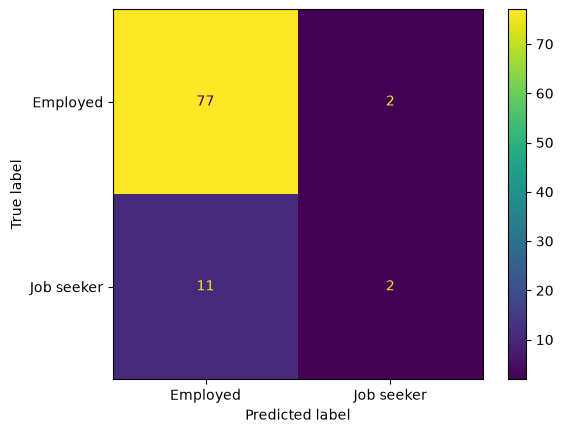

In [113]:
# [Figure 6] Confusion matrix on the test set
y_pred = logreg.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['Employed', 'Job seeker']).plot()
plt.show()

In [114]:
# [Table 13] Classification report on the test set
print(classification_report(y_test, y_pred, target_names=['Employed', 'Job seeker']))

              precision    recall  f1-score   support

    Employed       0.88      0.97      0.92        79
  Job seeker       0.50      0.15      0.24        13

    accuracy                           0.86        92
   macro avg       0.69      0.56      0.58        92
weighted avg       0.82      0.86      0.83        92



NOTE: The test set has 92 people, 13 of them job seekers. The model is right for 79 of the 92 (accuracy 85.9%), which is exactly the baseline: always saying "Employed" also gets 79 right. It flags only 4 people as job seekers, and only 2 of them really are (precision 0.50). So the recall of the job seekers is 2 out of 13, or 15%: the model misses 11 of the 13 job seekers. With only 13 job seekers in the test set, each person changes the recall by about 8 points, so this number is itself uncertain.

NOTE: Is the model useful? Not as a tool to find job seekers. An HR or outplacement team using it with the usual 0.5 threshold would miss about 85% of the job seekers and would do no better than assuming everyone is employed. The reason is that job seekers are few (15%) and their scores overlap a lot with those of the employed. The model is more useful as a description: it shows which characteristics go with being a job seeker (lower self-efficacy, more training, fewer children, no business school degree), even though it cannot pick out individuals.

### 4.5 Prediction is not causation

Job seekers score higher on training (+0.85) and networks (+0.65) than the employed, and training stays significant in the model (OR 1.35). But the questions do not all refer to the same time. Some training questions ask about plans: "I plan to follow a training programme in the near future", "I plan to follow a training programme as soon as possible, even at the cost of some sacrifices", "I will train in new technologies as soon as the opportunity arises". Planning to train is a natural reaction to losing a job, so here the job search most likely comes first. Other questions ask about the past ("I have already taken the initiative to follow a training programme"), and the networks questions all ask about past use ("I have already used current online professional networks (Viadeo, LinkedIn...)", "I have already used my network in the context of my job"). These past actions may have happened before or after the job loss, and the questionnaire does not say when.

The data come from one survey at one moment (cross-sectional data). They can show an association: job seekers train and network more. They cannot show the direction (does training lead to job seeking, or job seeking to training?) or a cause, and other factors (for example being made redundant and offered an outplacement programme with training) may explain both. To answer the question we would need longitudinal data, following the same executives over time with the dates of training, network use and job loss, or ideally an experiment where training or network support is offered at random.

## 5. Summary of results

- The sample is 457 senior executives (3 duplicates dropped), mostly business school graduates (80.3%) earning more than 99k (67.4%), so results may not hold for all senior executives (Table 1, Figure 1).
- Competence is very high for almost everyone (mean 6.32, ceiling effect), and self-efficacy is low on average (mean 3.55) but well spread (Table 2, Figure 2).
- All 12 scores are positively correlated, with r up to 0.58 and two groups of scores that go together (Figure 3).
- Personal variables are only weakly linked to the scores; the clearest link is older age with lower self-efficacy (r = -0.18) (Tables 3 and 4).
- Job seekers score higher on 10 of the 12 scores, mostly training and networks, but lower on self-efficacy (Table 5).
- The linear regression explains 45% of self-efficacy (R² = 0.448, adjusted 0.416). Flexibility and value awareness are the strongest predictors, followed by age and salary (Table 9, Figure 4).
- The ranking of the predictors is not firm: five scores change sign once the others are in the model, and most confidence intervals overlap (Table 10).
- In the logistic regression, lower self-efficacy, more training, fewer children and a degree outside business school go with higher odds of being a job seeker (Table 12).
- On the test set the model is no better than the baseline (accuracy 85.9% for both) and finds only 2 of the 13 job seekers (recall 15%) (Figure 6, Table 13).
- The data are cross-sectional: they show associations, not causes, so we cannot say whether training leads to job seeking or the other way round (Section 4.5).